# **Analyzing the Importance of Audio Features in Music Genre Classification Using Data Mining Techniques**

**Exploratory Data Analysis and Data Mining for the FMA-Small Dataset**
<br>
**Notebook by: Elia Fel P. Bado**

#**I. Introduction**





####**Data Source & Origin**
*   Repository Link: [FMA GitHub Repository](https://github.com/mdeff/fma)
*   Citation: Defferrard, M., Benzi, K., Vandergheynst, P., & Bresson, X. (2017). *FMA: A Dataset for Music Analysis*. arXiv:1612.01840.
<br>

####**Who collected the data, when, how, and for what purpose?**
* The dataset was created by Michaël Defferrard, Kirell Benzi, Pierre Vandergheynst, and Xavier Bresson in 2017 for the 18th International Society for Music Information Retrieval Conference (ISMIR). It was designed to provide an open, easily accessible audio dataset for evaluating tasks in Music Information Retrieval (MIR), aiming to overcome hurdles from the limited availability of large public audio datasets. The data was collected by querying the Free Music Archive (FMA) web API.
<br>

####**What does one row represent?**
* `tracks.csv`: One row represents a single music track.
* `features.csv`: One row represents extracted audio features (via librosa) for a track.
<br>

####**What does each column mean?**
* `tracks.csv`: Contains track metadata such as track ID, title, artist, genres, tags, and play counts.
* `features.csv`: Contains statistical descriptors of common audio features extracted using `librosa` (e.g., MFCCs, spectral centroid, chroma).

<br>

####**Questions to Explore**
1.   How accurately can baseline machine learning models perform genre recognition using extracted audio features vs. raw audio?
2.   How does the hierarchical genre taxonomy affect classification performance across top-level genres?
3.   Can representation learning on artist labels transfer effectively to genre classification tasks?
4.   How do Echonest audio features compare with librosa-extracted features in predicting track play counts?

In [1]:
import os

# connecting colab to gdrive, check if folder exists, and return folder size
from google.colab import drive
drive.mount('/content/drive')

#paths
base_path = '/content/drive/MyDrive/Music_Genre_Classification'
dataset_path = os.path.join(base_path, 'dataset')

raw_dataset_path = os.path.join(dataset_path, 'raw')
fma_metadata_path = os.path.join(raw_dataset_path, 'fma_metadata')
fma_small_path = os.path.join(raw_dataset_path, 'fma_small')

processed_dataset_path = os.path.join(dataset_path, 'processed')


#for fetching folder size
def get_dir_size(path):
    total_size = 0
    for dirpath, dirnames, filenames in os.walk(path):
        for f in filenames:
            fp = os.path.join(dirpath, f)
            if not os.path.islink(fp):
                total_size += os.path.getsize(fp)
    return total_size

#to check if folders has contents
folder_exists = os.path.exists(base_path)
print(f"Music_Genre_Classification file exists: {folder_exists}")
print(f"dataset/raw/fma_metadata exists: {os.path.exists(fma_metadata_path)}")
print(f"dataset/raw/fma_small exists: {os.path.exists(fma_small_path)}")

if folder_exists:
    fma_metadata_file_size = (get_dir_size(fma_metadata_path))/(1024*1024)
    fma_small_file_size = (get_dir_size(fma_small_path))/(1024*1024)
    print(f"fma_metadata Folder Size: {fma_metadata_file_size:.2f} MB")
    print(f"fma_small Folder Size: {fma_small_file_size:.2f} MB")
else:
    print("Folder Size: N/A")

Mounted at /content/drive
Music_Genre_Classification file exists: True
dataset/raw/fma_metadata exists: True
dataset/raw/fma_small exists: True
fma_metadata Folder Size: 1396.98 MB
fma_small Folder Size: 7606.00 MB


# **II. Data loading and first look**

This section loads and inspects the two core tables needed for FMA-Small genre analysis: `tracks.csv` (track metadata, dataset splits, and top-level genre labels) and `features.csv` (518 pre-extracted `librosa` audio descriptors per track). Both files are parsed with their multi-index headers, filtered and index-aligned to the 8,000-track `fma-small` subset, and reviewed for shape, sample records, data types, summary statistics, and variable classifications to establish a verified baseline before data quality checks.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import Markdown

In [3]:
# DATA LOADING FOR tracks.csv

tracks_path = os.path.join(fma_metadata_path, 'tracks.csv')

# load the raw metadata handling the multi-index header
tracks = pd.read_csv(tracks_path, index_col=0, header=[0, 1])

# filtering the tracks to tee fma-small dataset
small_tracks = tracks[tracks[('set', 'subset')] == 'small']

#print the shape, sample, info, and description
display(Markdown("\n###--- **Tracks Shape ---**"))
print("Tracks Shape: ",small_tracks.shape)

display(Markdown("\n###--- **Tracks Random Sample (5 rows) ---**"))
display(small_tracks.sample(5, random_state=67))

display(Markdown("\n###--- **Tracks Info ---**"))
small_tracks.info()

display(Markdown("\n###--- **Tracks Description ---**"))
# Enable pandas to display all rows/columns so nothing gets truncated in the summary
with pd.option_context('display.max_rows', None, 'display.max_columns', None):
    display(small_tracks.describe(include='all').T)


###--- **Tracks Shape ---**

Tracks Shape:  (8000, 52)



###--- **Tracks Random Sample (5 rows) ---**

album                                                           \
         comments         date_created        date_released       engineer   
track_id                                                                     
60736           0  2012-02-16 12:21:38                  NaN            NaN   
35534           0  2010-09-13 21:34:29  2008-08-30 00:00:00  Mark Whitcomb   
131939          0  2016-02-05 17:24:58                  NaN            NaN   
71508           5  2012-10-19 17:36:21                  NaN            NaN   
76079           2  2013-01-14 16:39:08  2012-12-24 00:00:00            NaN   

                                                                              \
         favorites     id                                        information   
track_id                                                                       
60736            0  11111  <p><span style="color:#222222;font-family:Aria...   
35534            1   7319                                            <p></p>   
131939           0  19874  <p>Psychedelic electric Albanian, Macedonian, ...   
71508            3  12672  <p style="margin: 0px; padding: 8px 0px; font-...   
76079            0  13312  <p>The Koliadnyky are a group of Hutsuls from ...   

                                                                              \
         listens producer                                               tags   
track_id                                                                       
60736      20604      NaN  ['live', 'newyx', 'suicidal birds', 'recipe bo...   
35534      30930      NaN                                                 []   
131939      8794      NaN                                                 []   
71508     115471      NaN                                    ['peter swimm']   
76079      10119      NaN  ['trembita', 'ukraine', 'tsymbaly', 'koliadnyk...   

          ...       track                         \
          ... information interest language_code   
track_id  ...                                      
60736     ...         NaN     9012           NaN   
35534     ...         NaN     6328           NaN   
131939    ...         NaN     1041           NaN   
71508     ...         NaN     6193           NaN   
76079     ...         NaN     1105           NaN   

                                                                              \
                                                    license listens lyricist   
track_id                                                                       
60736     Attribution-Noncommercial-Share Alike 3.0 Unit...    7628      NaN   
35534              Attribution-ShareAlike 3.0 International    3553      NaN   
131939    Creative Commons Attribution-NonCommercial-NoD...     867      NaN   
71508                          Creative Commons Attribution    4609      NaN   
76079     Attribution-NonCommercial-NoDerivatives (aka M...     979      NaN   

                                                                              \
         number publisher                                               tags   
track_id                                                                       
60736        10       NaN  ['live', 'newyx', 'suicidal birds', 'recipe bo...   
35534        11       NaN                                                 []   
131939        1       NaN                                                 []   
71508         9       NaN                                    ['peter swimm']   
76079        13       NaN  ['trembita', 'ukraine', 'tsymbaly', 'koliadnyk...   

                                                             
                                                      title  
track_id                                                     
60736                   Mexican Holiday live at the Winston  
35534                                          Feed The One  
131939                                 Rreth e qark beratit  
71508                             


###--- **Tracks Info ---**

<class 'pandas.core.frame.DataFrame'>
Index: 8000 entries, 2 to 155066
Data columns (total 52 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   (album, comments)            8000 non-null   int64  
 1   (album, date_created)        8000 non-null   object 
 2   (album, date_released)       5337 non-null   object 
 3   (album, engineer)            1142 non-null   object 
 4   (album, favorites)           8000 non-null   int64  
 5   (album, id)                  8000 non-null   int64  
 6   (album, information)         6502 non-null   object 
 7   (album, listens)             8000 non-null   int64  
 8   (album, producer)            1404 non-null   object 
 9   (album, tags)                8000 non-null   object 
 10  (album, title)               8000 non-null   object 
 11  (album, tracks)              8000 non-null   int64  
 12  (album, type)                7769 non-null   object 
 13  (artist, active_year_


###--- **Tracks Description ---**

count unique  \
album  comments           8000.0    NaN   
       date_created         8000   2459   
       date_released        5337   1223   
       engineer             1142    145   
       favorites          8000.0    NaN   
       id                 8000.0    NaN   
       information          6502   1942   
       listens            8000.0    NaN   
       producer             1404    191   
       tags                 8000    378   
       title                8000   2417   
       tracks             8000.0    NaN   
       type                 7769      4   
artist active_year_begin    1542     49   
       active_year_end       358     32   
       associated_labels     849    180   
       bio                  5914   1357   
       comments           8000.0    NaN   
       date_created         8000   2301   
       favorites          8000.0    NaN   
       id                 8000.0    NaN   
       latitude           2899.0    NaN   
       location             5471    754   
       longitude          2899.0    NaN   
       members              3525    865   
       name                 8000   2306   
       related_projects      694    171   
       tags                 8000   2262   
       website              6452   1481   
       wikipedia_page        410    102   
set    split                8000      3   
       subset               8000      1   
track  bit_rate           8000.0    NaN   
       comments           8000.0    NaN   
       composer              180     68   
       date_created         8000   7000   
       date_recorded         465    116   
       duration           8000.0    NaN   
       favorites          8000.0    NaN   
       genre_top            8000      8   
       genres               8000    586   
       genres_all           8000    442   
       information           159    112   
       interest           8000.0    NaN   
       language_code        1005     13   
       license              7995     62   
       listens            8000.0    NaN   
       lyricist               26     12   
       number             8000.0    NaN   
       publisher              76     19   
       tags                 8000    378   
       title                8000   7767   

                                                                        top  \
album  comments                                                         NaN   
       date_created                                     2015-05-21 17:43:17   
       date_released                                    2007-01-01 00:00:00   
       engineer                                                Irene Trudel   
       favorites                                                        NaN   
       id                                                               NaN   
       information                    <p>Instrumental - Various styles.</p>   
       listens                                                          NaN   
       producer                                                Rob Weisberg   
       tags                                                              []   
       title                               Live at the 2014 Golden Festival   
       tracks                                                           NaN   
       type                                                           Album   
artist active_year_begin                                2008-01-01 00:00:00   
       active_year_end                                  2015-01-01 00:00:00   
       associated_labels  Time-Lag, Phase!, Feeding Tube, Peasant Magik,...   
       bio                <p><a title="Blue Dot Website" href="/contribu...   
       comments                                                         NaN   
       date_created                                     2015-02-03 12:05:36   
       favorites                                                        NaN   
       id                                                               NaN   
       la

In [4]:
# DATA LOADING FOR features.csv

features_path = os.path.join(fma_metadata_path, 'features.csv')

# load the raw metadata handling the multi-index header
features = pd.read_csv(features_path, index_col=0, header=[0, 1, 2])

#filter features to match the track_ids of the small subset
small_features = features.loc[small_tracks.index]

#print the shape, sample, and info
display(Markdown("\n###--- **Features Shape ---**"))
print("Features Shape: ",small_features.shape)

display(Markdown("\n###--- **Features Random Sample (5 rows) ---**"))
display(small_features.sample(5, random_state=67))

display(Markdown("\n###--- **Features Info ---**"))
small_features.info()

display(Markdown("\n###--- **Features Description ---**"))
# Enable pandas to display all rows/columns so nothing gets truncated in the summary
with pd.option_context('display.max_rows', None, 'display.max_columns', None):
    display(small_features.describe(include='all').T)


###--- **Features Shape ---**

Features Shape:  (8000, 518)



###--- **Features Random Sample (5 rows) ---**

feature    chroma_cens                                                    \
statistics    kurtosis                                                     
number              01        02        03        04        05        06   
track_id                                                                   
60736         3.666378  4.473220  4.830767  1.744571  1.397857  1.820356   
35534        -0.647455 -0.984537 -0.435043 -0.678039 -0.683269  0.023716   
131939       -1.180873 -0.374147 -1.011606 -0.172726 -0.229813  0.281381   
71508         1.639837 -1.019516  0.208297  3.664822  1.336885  0.702219   
76079        -1.134631 -0.795856 -1.140404 -1.008961  1.580629 -0.199513   

feature                                             ...   tonnetz            \
statistics                                          ...       std             
number            07        08        09        10  ...        04        05   
track_id                                            ...                       
60736       1.757500  4.938700  0.215622 -0.046953  ...  0.044820  0.015213   
35534      -0.257244 -0.170678  0.088068 -0.125568  ...  0.092387  0.019067   
131939     -0.905243  0.048887 -0.177934  0.298722  ...  0.121513  0.025258   
71508       3.188430  1.107264 -0.845742  0.570397  ...  0.068503  0.031183   
76079      -0.664471 -0.564692 -0.145973  0.189562  ...  0.111757  0.018231   

feature                     zcr                                          \
statistics             kurtosis       max      mean    median       min   
number            06         01        01        01        01        01   
track_id                                                                  
60736       0.011291   0.315925  0.107910  0.066835  0.067383  0.014160   
35534       0.018861  10.991987  0.349609  0.064351  0.056152  0.008789   
131939      0.022618   4.100006  0.149414  0.034082  0.030273  0.001953   
71508       0.014314   3.373695  0.228027  0.054972  0.052246  0.002441   
76079       0.019553   9.288609  0.406738  0.075960  0.060059  0.013184   

feature                         
statistics      skew       std  
number            01        01  
track_id                        
60736      -0.353675  0.012615  
35534       2.836525  0.037081  
131939      1.676785  0.015956  
71508       1.088970  0.025137  
76079       2.881972  0.056434  

[5 rows x 518 columns]


###--- **Features Info ---**

<class 'pandas.core.frame.DataFrame'>
Index: 8000 entries, 2 to 155066
Columns: 518 entries, ('chroma_cens', 'kurtosis', '01') to ('zcr', 'std', '01')
dtypes: float64(518)
memory usage: 31.7 MB



###--- **Features Description ---**

count         mean          std  \
feature            statistics number                                     
chroma_cens        kurtosis   01      8000.0     0.111983     1.656377   
                              02      8000.0     0.007180     1.934319   
                              03      8000.0     0.200494     6.073813   
                              04      8000.0     0.005261     1.288859   
                              05      8000.0     0.067485     1.636802   
                              06      8000.0     0.077369     1.599574   
                              07      8000.0     0.021349     2.086226   
                              08      8000.0     0.139799     2.983964   
                              09      8000.0     0.012609     1.810619   
                              10      8000.0     0.091662     1.984203   
                              11      8000.0     0.178579     5.393973   
                              12      8000.0     0.135284     2.260764   
                   max        01      8000.0     0.625050     0.081653   
                              02      8000.0     0.593938     0.080088   
                              03      8000.0     0.614813     0.085414   
                              04      8000.0     0.591072     0.083029   
                              05      8000.0     0.613068     0.084733   
                              06      8000.0     0.601139     0.087980   
                              07      8000.0     0.593704     0.084820   
                              08      8000.0     0.618332     0.085818   
                              09      8000.0     0.593066     0.082448   
                              10      8000.0     0.613302     0.089511   
                              11      8000.0     0.592615     0.087695   
                              12      8000.0     0.602501     0.086897   
                   mean       01      8000.0     0.251411     0.081668   
                              02      8000.0     0.247304     0.073219   
                              03      8000.0     0.246081     0.083013   
                              04      8000.0     0.248013     0.072828   
                              05      8000.0     0.251655     0.080661   
                              06      8000.0     0.243285     0.074201   
                              07      8000.0     0.243659     0.069708   
                              08      8000.0     0.251214     0.078578   
                              09      8000.0     0.250265     0.070979   
                              10      8000.0     0.242505     0.080035   
                              11      8000.0     0.231333     0.072339   
                              12      8000.0     0.229890     0.075132   
                   median     01      8000.0     0.241075     0.097057   
                              02      8000.0     0.239812     0.087417   
                              03      8000.0     0.234581     0.099444   
                              04      8000.0     0.240343     0.086907   
                              05      8000.0     0.241656     0.096697   
                              06      8000.0     0.233047     0.088789   
                              07      8000.0     0.235382     0.083456   
                              08      8000.0     0.240620     0.093835   
                              09      8000.0     0.243980     0.084434   
                              10      8000.0     0.229967     0.096487   
                              11      8000.0     0.220313     0.086823   
                              12      8000.0     0.217519     0.090408   
                   min        01      8000.0     0.007271     0.028201   
                              02      8000.0     0.007201     0.027493   
                              03      8000.0     0.006771     0.026500   
                              04      8000.0     0.007337     0.026097   
                              05      8000.

### **Variable Classification Schema & Rules**
This framework establishes which statistical summaries and visualization plots are valid for each data category in the dataset:

| Variable type | Examples | Summaries | Plots |
| :--- | :--- | :--- | :--- |
| Continuous numeric | `track/duration`, `features.csv` (all 518 float64 audio metrics like MFCC mean, chroma std, spectral centroid) | Mean, Median, Standard Deviation, Min/Max, Percentiles, Skewness, Kurtosis | Histograms, Kernel Density Estimate (KDE) plots, Box plots, Violin plots |
| Discrete numeric (counts) | `album/comments`, `album/favorites`, `artist/comments`, `track/favorites`, `track/interest`, `track/listens` | Median, Mode, Range, Min/Max, Frequency distributions | Bar charts, Rootograms, Frequency polygons, Step plots |
| Nominal categorical | `track/genre_top`, `track/license`, `album/type`, `track/language_code` | Frequency counts, Mode, Percentages, Contingency tables (for relationships) | Bar plots (ordered by frequency), Pie charts, Countplots |
| Ordinal categorical | `set/subset` (small < medium < large) | Median, Mode, Cumulative frequencies, Percentages | Ordered bar charts, Cumulative distribution frequency line plots |
| Binary | Dummy encoded features, or custom splits (e.g., `is_instrumental` from track genres/tags) | Proportions, Mode, Success/Failure rates | Bar charts, Pie charts, Stacked bar charts |
| Date/time | `album/date_created`, `album/date_released`, `artist/date_created`, `track/date_created` | Minimum/Maximum date, Range, Seasonality/Trend decompositions | Time series line plots, Seasonal subseries plots, Calendar heatmaps |
| Free text | `track/title`, `artist/bio`, `album/information`, `artist/name`, `track/tags` | Word counts, Character lengths, Most frequent tokens/n-grams, Lexicon analysis | Word clouds, Bar charts of top terms, Text length histograms |
| Identifier | `track_id` (Index), `album/id`, `artist/id` | Uniqueness ratio, Total count, Cardinality | None (strictly used for join keys and record reference) |

### **Key Takeaways**

#### **1. Row & Column Count Verification Against FMA Source Specification**
* **`tracks.csv` (`small_tracks`):** Loaded with **8,000 rows × 52 columns** under a 2-level multi-index (`album`, `artist`, `set`, `track`) and indexed by `track_id` (`2` to `155066`). This matches the official FMA-Small benchmark specification: exactly 8,000 tracks (`set / subset` has 1 unique value, `'small'`), 8 top-level genres (`track / genre_top` has 8 unique values, with 1,000 tracks in the top class), and 3 predefined partitions (`set / split`, with 6,400 tracks in `'training'`).
* **`features.csv` (`small_features`):** Loaded with **8,000 rows × 518 columns** under a 3-level multi-index (`feature`, `statistics`, `number`) spanning `('chroma_cens', 'kurtosis', '01')` to `('zcr', 'std', '01')`. This matches the FMA source specification of 518 pre-extracted `librosa` audio descriptors and aligns 1-to-1 with `small_tracks` on `track_id`, with 8,000 non-null entries in every column.

#### **2. Data Type Verification & Parsing Checks**
* **Audio features (`small_features` — 518 `float64`):** All 518 feature columns were read cleanly as continuous `float64` values (31.7 MB), confirming **no numeric features were stored as text**.
* **Numeric metadata (`small_tracks` — 15 `int64`, 2 `float64`):** All true numeric counts and measurements (`bit_rate`, `duration`, `listens`, `favorites`, `comments`, `interest`, `tracks`, `number`, and `latitude`/`longitude`) loaded with appropriate numeric types, with **no scalar numbers misread as text**.
* **Dates read as strings (`object`) — Requires conversion:** All **7 temporal columns** were read as plain strings (`YYYY-MM-DD HH:MM:SS`) instead of `datetime64`: `('album', 'date_created')`, `('album', 'date_released')`, `('artist', 'date_created')`, `('artist', 'active_year_begin')`, `('artist', 'active_year_end')`, `('track', 'date_created')`, and `('track', 'date_recorded')`. These require `pd.to_datetime()` parsing before temporal analysis (notably, `active_year_begin` and `active_year_end` are stored as full timestamps rather than integer years).
* **ID codes read as numbers (`int64`) — Do not treat as numeric:** `('album', 'id')` and `('artist', 'id')` (along with the `track_id` index) were read as `int64`, causing `describe()` to compute meaningless averages (e.g., mean `album/id` = 13,529.0; mean `artist/id` = 12,984.2). They must be treated strictly as nominal identifiers/join keys rather than quantitative variables.
* **Serialized lists, categoricals, and HTML text (`object`):** Five list-valued columns—`('track', 'genres')`, `('track', 'genres_all')`, `('album', 'tags')`, `('artist', 'tags')`, and `('track', 'tags')`—were read as literal list strings (e.g., `[21]`, `[]`) and would require `ast.literal_eval()` if unpacked. Low-cardinality categoricals (`genre_top`, `split`, `subset`, `album/type`, `language_code`) loaded as `object` and can be cast to `category`, while free-text fields (`album/information`, `artist/bio`, `track/information`) contain embedded HTML markup.

# **III. Data quality assessment**

This section audits the integrity and reliability of `small_tracks` and `small_features` before any cleaning is applied. It systematically checks both tables for missing values, duplicate records and track IDs, inconsistent categorical levels, and logically or numerically impossible values (such as non-positive durations, infinite values, or negative standard deviations). It then tests whether metadata missingness is random or structurally biased across genres and time, and inspects flagged outliers (via the 1.5 × IQR rule and `|z| > 3`) at the row level to separate true data or extraction errors from genuine extreme recordings—directly informing the cleaning decisions in the next section.

## **III.1 Completeness, Duplicates & Validity Checks (`small_tracks` & `small_features`)**

Audits both tables for missing values, duplicate rows and track IDs, categorical level consistency, and logically or numerically impossible values—including non-positive track durations in `small_tracks` as well as infinite values and negative standard deviations across the 518 audio descriptors in `small_features`.

In [ ]:
#tracks.csv

# Missing values: count and percent per column
print("--- Missing Values ---")
missing = small_tracks.isna().sum().to_frame("n_missing")
missing["pct"] = (missing["n_missing"] / len(small_tracks) * 100).round(1)
display(missing.sort_values("pct", ascending=False).head(20))

# Duplicate rows and duplicate IDs
print("\n--- Duplicate Rows and Duplicate IDs ---")
print(f"Duplicate rows in tracks: {small_tracks.duplicated().sum()}")
print(f"Duplicate track IDs in tracks (Index): {small_tracks.index.duplicated().sum()}")

# Categorical levels: look for typos, mixed case, stray spaces
print("\n--- Categorical Levels ---")
print("Unique values per column")
for col in small_tracks.select_dtypes("object").columns:
    print(col, small_tracks[col].nunique(), small_tracks[col].unique()[:5])

# Impossible values: check against what is physically or logically possible (e.g. non-positive duration)
print("\n--- Impossible Values ---")
impossible_durations = small_tracks[small_tracks[("track", "duration")] <= 0]
print(f"Tracks with non-positive duration: {len(impossible_durations)}")

# Displaying the 16 tracks with a duration of 0 or less
if len(impossible_durations) > 0:
    print("\n--- Impossible Duration Tracks ---")
    impossible_tracks_view = impossible_durations[[
        ('track', 'title'),
        ('artist', 'name'),
        ('track', 'duration'),
        ('set', 'subset')
    ]]
    display(impossible_tracks_view)

--- Missing Values ---


n_missing   pct
track  lyricist                7974  99.7
       publisher               7924  99.1
       information             7841  98.0
       composer                7820  97.8
artist active_year_end         7642  95.5
       wikipedia_page          7590  94.9
track  date_recorded           7535  94.2
artist related_projects        7306  91.3
       associated_labels       7151  89.4
track  language_code           6995  87.4
album  engineer                6858  85.7
       producer                6596  82.4
artist active_year_begin       6458  80.7
       longitude               5101  63.8
       latitude                5101  63.8
       members                 4475  55.9
album  date_released           2663  33.3
artist location                2529  31.6
       bio                     2086  26.1
       website                 1548  19.4


--- Duplicate Rows and Duplicate IDs ---
Duplicate rows in tracks: 0
Duplicate track IDs in tracks (Index): 0

--- Categorical Levels ---
Unique values per column
('album', 'date_created') 2459 ['2008-11-26 01:44:45' '2008-11-26 01:45:08' '2008-11-26 01:49:59'
 '2008-11-26 01:49:57' '2008-11-26 01:50:19']
('album', 'date_released') 1223 ['2009-01-05 00:00:00' '2008-02-06 00:00:00' '2007-05-22 00:00:00'
 '2009-01-16 00:00:00' '2009-01-15 00:00:00']
('album', 'engineer') 145 [nan 'self-recorded' 'Michael Goodstein' 'Irene Trudel' 'Scott Williams']
('album', 'information') 1942 ['<p></p>' nan
 '<p>Alec K. Redfearn &amp; The Eyesores: Ellen Santaniello (soprano); Domenick Panzarella (guitar); Steve Jobe (hurdy-gurdy); Sarah Tolan-Mee, Olivia Geiger (violin); Laura Gulley (viola); Alec K. Redfearn (accordion); Erica Schattle (bassoon); Jason <span id="switchNoteSnippet" style="display: none;">...&nbsp;&nbsp;&nbsp; <a class="notimportantlink" style="cursor: pointer;" onclick="javascript:sho

In [ ]:
# features.csv

# 1. Missing values: count and percent per column
print("--- Missing Values in Features ---")
missing = small_features.isna().sum().to_frame("n_missing")
missing["pct"] = (missing["n_missing"] / len(small_features) * 100).round(1)
display(missing.sort_values("pct", ascending=False).head(20))

# 2. Duplicate rows and duplicate IDs
print("\n--- Duplicate Rows and Duplicate Track IDs in Features ---")
print(f"Duplicate rows in features: {small_features.duplicated().sum()}")
print(f"Duplicate track IDs (Index): {small_features.index.duplicated().sum()}")

# 3. Numeric boundaries: check for Infinite values, which can disrupt machine learning models
print("\n--- Infinite Values check ---")
inf_counts = np.isinf(small_features).sum().sum()
print(f"Total infinite (inf / -inf) values: {inf_counts}")

# 4. Check for invalid feature metrics (like negative standard deviations)
print("\n--- Statistical Sanity Check ---")
# Extracting columns that represent standard deviation
std_cols = [col for col in small_features.columns if col[1] == 'std']
invalid_stds = (small_features[std_cols] < 0).sum().sum()
print(f"Standard deviation columns with negative values: {invalid_stds}")

--- Missing Values in Features ---


n_missing  pct
feature     statistics number                
chroma_cens kurtosis   01              0  0.0
                       02              0  0.0
                       03              0  0.0
                       04              0  0.0
                       05              0  0.0
                       06              0  0.0
                       07              0  0.0
                       08              0  0.0
                       09              0  0.0
                       10              0  0.0
                       11              0  0.0
                       12              0  0.0
            max        01              0  0.0
                       02              0  0.0
                       03              0  0.0
                       04              0  0.0
                       05              0  0.0
                       06              0  0.0
                       07              0  0.0
                       08              0  0.0


--- Duplicate Rows and Duplicate Track IDs in Features ---
Duplicate rows in features: 17
Duplicate track IDs (Index): 0

--- Infinite Values check ---
Total infinite (inf / -inf) values: 0

--- Statistical Sanity Check ---
Standard deviation columns with negative values: 0


### **Summary of the Data Quality Assessment Results**

**1. `tracks.csv` (`small_tracks`, 8,000 rows)**

**Missing Values:** There is an extremely high percentage of missing values (> 90%) in optional metadata columns such as `('track', 'lyricist')` (99.7%), `('track', 'publisher')` (99.1%), `('track', 'information')` (98.0%), `('track', 'composer')` (97.8%), `('artist', 'active_year_end')` (95.5%), `('artist', 'wikipedia_page')` (94.9%), `('track', 'date_recorded')` (94.2%), and `('artist', 'related_projects')` (91.3%). These can be safely ignored or dropped during cleaning. `('track', 'genre_top')` has **0 missing values (0.0%)** in the `fma_small` subset.

**Duplicates:**  There are no duplicate rows nor are there duplicate track IDs. The dataset has strong row integrity with unique track identifiers.

**Impossible Values:**  There are **0 tracks** with a duration of 0 or less in `small_tracks` (all durations fall between 60 and 600 seconds), so no impossible-duration rows need to be removed.

<br>

**2. `features.csv` (`small_features`, 8,000 rows)**

**Missing Values:**  There are no missing values (0.0% missing) across all 518 feature columns.

**Duplicates:**  There are 17 duplicated feature rows, meaning 17 tracks have mathematically identical feature representations, which might indicate duplicated audio files or redundant clips in the small subset.

**Impossible Values:**   There are no infinite values or negative standard deviations present to disrupt the model, confirming basic numerical validity across all 518 feature columns.

## **III.2 Missingness Pattern Analysis (`small_tracks`)**

Tests whether missing metadata values occur at random or systematically depend on other variables (`track / genre_top`, `album / type`, upload year, and engagement metrics). Because `small_features` has 0.0% missingness across all 518 columns, this check focuses on `small_tracks`.

In [ ]:
# @title
# --- Missingness Pattern Analysis (small_tracks) ---
# (small_features has 0 missing values across all 518 columns)

missing_cols = [
    ('album', 'date_released'),
    ('artist', 'location'),
    ('artist', 'latitude'),
    ('artist', 'bio'),
    ('album', 'information'),
    ('track', 'language_code'),
    ('album', 'type'),
]

track_year = pd.to_datetime(small_tracks[('track', 'date_created')], errors='coerce').dt.year

print('=== 1. Missingness Rate (%) by Top Genre ===')
genre_miss = pd.DataFrame({
    ' / '.join(col): small_tracks[col].isna().groupby(small_tracks[('track', 'genre_top')]).mean() * 100
    for col in missing_cols
}).round(1)
display(genre_miss)

print('\n=== 2. Chi-Square Independence Test: Missingness vs. Genre ===')
chi2_rows = []
for col in missing_cols:
    ct = pd.crosstab(small_tracks[col].isna(), small_tracks[('track', 'genre_top')])
    chi2, p, dof, _ = stats.chi2_contingency(ct)
    chi2_rows.append({
        'column': ' / '.join(col),
        'missing_pct': round(small_tracks[col].isna().mean() * 100, 1),
        'chi2': round(chi2, 2),
        'p_value': f'{p:.2e}'
    })
display(pd.DataFrame(chi2_rows))

print('\n=== 3. Rows With vs. Without Missing Values on Numeric & Temporal Columns (Medians) ===')
comp_rows = []
for col in [('album', 'date_released'), ('artist', 'location'), ('artist', 'latitude'), ('track', 'language_code')]:
    is_na = small_tracks[col].isna()
    comp_rows.append({
        'column': ' / '.join(col),
        'median_listens_missing': small_tracks.loc[is_na, ('track', 'listens')].median(),
        'median_listens_present': small_tracks.loc[~is_na, ('track', 'listens')].median(),
        'median_duration_missing': small_tracks.loc[is_na, ('track', 'duration')].median(),
        'median_duration_present': small_tracks.loc[~is_na, ('track', 'duration')].median(),
        'median_year_missing': track_year[is_na].median(),
        'median_year_present': track_year[~is_na].median(),
    })
display(pd.DataFrame(comp_rows))

print('\n=== 4. Co-missingness & Structural Checks ===')
lat_lon_match = (small_tracks[('artist', 'latitude')].isna() == small_tracks[('artist', 'longitude')].isna()).mean() * 100
loc_na_implies_lat_na = small_tracks.loc[small_tracks[('artist', 'location')].isna(), ('artist', 'latitude')].isna().mean() * 100
print(f'latitude and longitude missingness identical: {lat_lon_match:.1f}%')
print(f'When artist/location is missing, artist/latitude is also missing: {loc_na_implies_lat_na:.1f}%')
print('\nMissingness of album/date_released (%) by album/type:')
display((small_tracks[('album', 'date_released')].isna().groupby(small_tracks[('album', 'type')].fillna('Missing')).mean() * 100).round(1))

=== 1. Missingness Rate (%) by Top Genre ===


,album / date_released,artist / location,artist / latitude,artist / bio,album / information,track / language_code,album / type
"(track, genre_top)",,,,,,,
Electronic,35.2,35.7,69.0,41.0,17.8,95.6,4.4
Experimental,34.2,39.1,55.8,35.5,19.1,88.4,2.4
Folk,29.4,20.2,71.2,20.6,18.7,80.0,3.6
Hip-Hop,28.6,34.9,61.4,16.5,22.9,85.3,0.7
Instrumental,44.0,42.6,82.2,21.5,15.0,96.3,3.7
International,36.7,34.9,54.4,20.5,13.5,83.1,3.4
Pop,28.1,24.2,55.2,32.6,22.3,87.3,2.3
Rock,30.1,21.3,60.9,20.4,20.5,83.5,2.6



=== 2. Chi-Square Independence Test: Missingness vs. Genre ===


,column,missing_pct,chi2,p_value
0,album / date_released,33.3,92.34,4.10e-17
1,artist / location,31.6,234.35,5.90e-47
2,artist / latitude,63.8,286.00,5.88e-58
3,artist / bio,26.1,290.54,6.34e-59
4,album / information,18.7,49.63,1.71e-08
5,track / language_code,87.4,218.78,1.20e-43
6,album / type,2.9,32.70,3.01e-05



=== 3. Rows With vs. Without Missing Values on Numeric & Temporal Columns (Medians) ===


,column,median_listens_missing,median_listens_present,median_duration_missing,median_duration_present,median_year_missing,median_year_present
0,album / date_released,2779.0,2354.0,206.0,220.0,2013.0,2013.0
1,artist / location,2458.0,2503.0,215.0,215.0,2013.0,2013.0
2,artist / latitude,2611.0,2210.0,215.0,215.0,2014.0,2011.0
3,track / language_code,2572.0,1890.0,214.0,223.0,2014.0,2009.0



=== 4. Co-missingness & Structural Checks ===
latitude and longitude missingness identical: 100.0%
When artist/location is missing, artist/latitude is also missing: 99.2%

Missingness of album/date_released (%) by album/type:


,album
,date_released
"(album, type)",
Album,33.2
Live Performance,42.8
Missing,77.9
Radio Program,8.7
Single Tracks,9.9


## **III.3 Outlier Detection & Row-Level Inspection (`small_tracks` & `small_features`)**

Flags outliers using both the **1.5 × IQR rule** and **z-scores (`|z| > 3`)**, then inspects the actual extreme rows so each group of outliers can be classified as either a **data/extraction error** (fix or remove) or a **real extreme value** (keep and note).

In [ ]:
# --- Outlier Detection (IQR Rule & Z-Scores) and Actual-Row Inspection ---

def outlier_summary(df, cols):
    rows = []
    for col in cols:
        s = df[col].dropna()
        q1, q3 = s.quantile(0.25), s.quantile(0.75)
        iqr = q3 - q1
        low_f, high_f = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        n_iqr_low = int((s < low_f).sum())
        n_iqr_high = int((s > high_f).sum())
        n_iqr = n_iqr_low + n_iqr_high
        z = (s - s.mean()) / s.std(ddof=0) if s.std(ddof=0) > 0 else pd.Series(0, index=s.index)
        n_z3 = int((z.abs() > 3).sum())
        rows.append({
            'column': ' / '.join(col),
            'min': round(float(s.min()), 4),
            'median': round(float(s.median()), 4),
            'max': round(float(s.max()), 4),
            'iqr_low_fence': round(float(low_f), 4),
            'iqr_high_fence': round(float(high_f), 4),
            'iqr_outliers': n_iqr,
            'iqr_pct': round(n_iqr / len(s) * 100, 2),
            'iqr_low / high': f'{n_iqr_low} / {n_iqr_high}',
            'z_gt_3': n_z3,
            'z_gt_3_pct': round(n_z3 / len(s) * 100, 2),
        })
    return pd.DataFrame(rows)

# 1. Outlier summary for key numeric columns in small_tracks
track_num_cols = [
    ('track', 'duration'),
    ('track', 'bit_rate'),
    ('track', 'listens'),
    ('track', 'favorites'),
    ('track', 'interest'),
    ('track', 'number'),
    ('album', 'tracks'),
]
print('=== 1. Outlier Summary: small_tracks (IQR 1.5x & |Z| > 3) ===')
display(outlier_summary(small_tracks, track_num_cols))

# 2. Outlier summary for representative audio features in small_features
feat_num_cols = [
    ('spectral_centroid', 'mean', '01'),
    ('spectral_bandwidth', 'mean', '01'),
    ('spectral_rolloff', 'mean', '01'),
    ('spectral_contrast', 'mean', '01'),
    ('mfcc', 'mean', '01'),
    ('rmse', 'mean', '01'),
    ('zcr', 'mean', '01'),
    ('chroma_cens', 'mean', '01'),
    ('tonnetz', 'mean', '01'),
]
print('\n=== 2. Outlier Summary: small_features (IQR 1.5x & |Z| > 3) ===')
display(outlier_summary(small_features, feat_num_cols))

# 3. Inspect actual rows for the most notable flagged outliers in small_tracks
meta_view = [('track', 'title'), ('artist', 'name'), ('track', 'genre_top'), ('track', 'duration'), ('track', 'bit_rate'), ('track', 'listens'), ('track', 'favorites'), ('album', 'tracks'), ('track', 'number')]

print('\n=== 3a. Actual Rows: Longest track/duration (Top 5) ===')
display(small_tracks.nlargest(5, ('track', 'duration'))[meta_view])

print('\n=== 3b. Actual Rows: Highest track/listens (Top 5) ===')
display(small_tracks.nlargest(5, ('track', 'listens'))[meta_view])

print('\n=== 3c. Actual Rows: Suspicious album/tracks <= 0 or >= 100, and track/number == 0 ===')
print('album/tracks == 0 count:', (small_tracks[('album', 'tracks')] == 0).sum())
print('album/tracks < 0 count:', (small_tracks[('album', 'tracks')] < 0).sum())
print('track/number == 0 count:', (small_tracks[('track', 'number')] == 0).sum())
display(small_tracks.nlargest(5, ('album', 'tracks'))[meta_view])

# 4. Inspect actual rows for extreme audio features (both low-energy/near-silent and high-energy/high-ZCR/high-centroid)
feat_inspect = small_tracks[[('track', 'title'), ('artist', 'name'), ('track', 'genre_top'), ('track', 'duration'), ('track', 'bit_rate')]].copy()
feat_inspect.columns = ['title', 'artist', 'genre_top', 'duration', 'bit_rate']
feat_inspect['rmse_mean'] = small_features[('rmse', 'mean', '01')]
feat_inspect['rmse_max'] = small_features[('rmse', 'max', '01')]
feat_inspect['zcr_mean'] = small_features[('zcr', 'mean', '01')]
feat_inspect['centroid_mean'] = small_features[('spectral_centroid', 'mean', '01')]
feat_inspect['mfcc01_mean'] = small_features[('mfcc', 'mean', '01')]

print('\n=== 4a. Actual Rows: Lowest rmse_mean (Potential Silent / Near-Silent Tracks) ===')
print('Tracks with rmse_mean < 0.05:', (feat_inspect['rmse_mean'] < 0.05).sum())
print('Tracks with rmse_max == 0:', (feat_inspect['rmse_max'] == 0).sum())
display(feat_inspect.nsmallest(10, 'rmse_mean'))

print('\n=== 4b. Actual Rows: Highest rmse_mean (Top 5) ===')
display(feat_inspect.nlargest(5, 'rmse_mean'))

print('\n=== 4c. Actual Rows: Highest zcr_mean (Top 5) ===')
display(feat_inspect.nlargest(5, 'zcr_mean'))

print('\n=== 4d. Actual Rows: Highest spectral_centroid_mean (Top 5) ===')
display(feat_inspect.nlargest(5, 'centroid_mean'))

print('\n=== 4e. Actual Rows: Lowest mfcc01_mean (Bottom 5) ===')
display(feat_inspect.nsmallest(5, 'mfcc01_mean'))

=== 1. Outlier Summary: small_tracks (IQR 1.5x & |Z| > 3) ===


,column,min,median,max,iqr_low_fence,iqr_high_fence,iqr_outliers,iqr_pct,iqr_low / high,z_gt_3,z_gt_3_pct
0,track / duration,60.0,215.0,600.0,-16.000,456.000,270,3.38,0 / 270,104,1.30
1,track / bit_rate,105237.0,263069.0,322541.0,52940.000,480236.000,0,0.00,0 / 0,0,0.00
2,track / listens,196.0,2492.5,543252.0,-4185.375,10351.625,666,8.33,0 / 666,58,0.73
3,track / favorites,0.0,3.0,1482.0,-8.000,16.000,668,8.35,0 / 668,31,0.39
4,track / interest,463.0,3491.5,3293557.0,-5516.500,14209.500,675,8.44,0 / 675,11,0.14
5,track / number,0.0,4.0,128.0,-7.000,17.000,248,3.10,0 / 248,119,1.49
6,album / tracks,1.0,9.0,47.0,-6.000,26.000,439,5.49,0 / 439,240,3.00



=== 2. Outlier Summary: small_features (IQR 1.5x & |Z| > 3) ===


,column,min,median,max,iqr_low_fence,iqr_high_fence,iqr_outliers,iqr_pct,iqr_low / high,z_gt_3,z_gt_3_pct
0,spectral_centroid / mean / 01,140.7543,1125.0632,5575.1079,-143.2347,2422.5436,152,1.90,0 / 152,73,0.91
1,spectral_bandwidth / mean / 01,241.7549,1410.1693,3789.3716,248.9414,2570.4622,94,1.18,1 / 93,42,0.53
2,spectral_rolloff / mean / 01,167.2468,2261.1451,9401.7715,-642.3630,5249.6648,132,1.65,0 / 132,70,0.88
3,spectral_contrast / mean / 01,10.3504,20.2677,38.5041,11.8932,28.9183,160,2.00,9 / 151,81,1.01
4,mfcc / mean / 01,-985.1136,-191.3494,138.3716,-440.8442,45.9062,131,1.64,114 / 17,60,0.75
5,rmse / mean / 01,0.0002,4.2863,21.6082,-2.1802,10.9276,114,1.43,0 / 114,81,1.01
6,zcr / mean / 01,0.0035,0.0461,0.6297,-0.0131,0.1083,247,3.09,0 / 247,104,1.30
7,chroma_cens / mean / 01,0.0039,0.2498,0.7059,0.0517,0.4476,182,2.27,41 / 141,57,0.71
8,tonnetz / mean / 01,-0.0946,0.0006,0.0774,-0.0291,0.0313,282,3.52,140 / 142,105,1.31



=== 3a. Actual Rows: Longest track/duration (Top 5) ===


track                            artist  \
                          title                              name   
track_id                                                            
80389                        a1                       A. P. Vague   
80402                        b3                       A. P. Vague   
122143    Genome Chomsky (pt I)  Anthony Donovan & Jaan Patterson   
133297       (piano & mosesa7C)                Balog and Matthies   
37731                  Limerick                        Bardo Pond   

                 track                                      album  track  
             genre_top duration bit_rate listens favorites tracks number  
track_id                                                                  
80389     Instrumental      600   320000    1687         6      9      1  
80402     Instrumental      600   320000    6135         2      9      6  
122143    Experimental      600   320000     807         0     37     12  
133297    Experimental      600   320000    2101         1     41      5  
37731             Rock      599   256000    2997         4      7      1

... (10 outputs left out)


=== 4d. Actual Rows: Highest spectral_centroid_mean (Top 5) ===


,title,artist,genre_top,duration,bit_rate,rmse_mean,rmse_max,zcr_mean,centroid_mean,mfcc01_mean
track_id,,,,,,,,,,
107535,Naked Skin,Vägskäl,Instrumental,285,192000,0.000246,0.000284,0.308617,5575.107910,-985.113586
46720,three lullabies 2,Eva-Maria Houben,Experimental,265,256000,0.030029,1.513148,0.222240,4708.514160,-689.867859
139687,nxI2016-06-30_04_56_08-A-2016-06-30_05_07_10,Miquel Parera & Computer,Experimental,359,320000,1.473745,6.955766,0.629665,4669.493652,-445.178497
139688,nxI2016-06-30_04_56_08-A-2016-06-30_05_13_15,Miquel Parera & Computer,Experimental,359,320000,1.926921,5.520841,0.427181,4402.260742,-325.939301
140266,Coco,Jorge Mario Zuleta,Experimental,419,128000,0.391109,1.182280,0.364355,4021.978027,-331.104614



=== 4e. Actual Rows: Lowest mfcc01_mean (Bottom 5) ===


,title,artist,genre_top,duration,bit_rate,rmse_mean,rmse_max,zcr_mean,centroid_mean,mfcc01_mean
track_id,,,,,,,,,,
107535,Naked Skin,Vägskäl,Instrumental,285,192000,0.000246,0.000284,0.308617,5575.107910,-985.113586
46717,three lullabies 3,Eva-Maria Houben,Experimental,408,256000,0.043083,1.006203,0.171643,3969.631348,-729.873657
46720,three lullabies 2,Eva-Maria Houben,Experimental,265,256000,0.030029,1.513148,0.222240,4708.514160,-689.867859
136928,Micro Black Death,Resonancedj,Experimental,450,320000,0.064723,1.646370,0.149710,3878.387695,-658.914368
51118,Tickled Pink,Bob Ostertag,Experimental,171,320000,0.078582,0.608574,0.064569,1557.781006,-654.403809


### **Missingness Pattern & Outlier Assessment**

#### **1. Missing Values: Random vs. Systematic Pattern (`small_tracks` & `small_features`)**

* **Are missing values random?** **No — missingness in `small_tracks` is systematically structured (not Missing Completely At Random / MCAR)**, whereas `small_features` has **0.0% missing values** across all 518 audio feature columns and the target variable `('track', 'genre_top')` has **0.0% missing values** in the `fma_small` subset.
* **Comparison across `track / genre_top`** (all chi-square tests of independence significant at $p < 3.1 \times 10^{-5}$, most $p < 10^{-16}$):
  * `track / language_code` (87.4% missing overall, $\chi^2 = 218.8, p = 1.20 \times 10^{-43}$): Missing for **96.3%** of `Instrumental` and **95.6%** of `Electronic` tracks, compared to **80.0%** of `Folk` and **83.1%** of `International` tracks — an expected domain pattern since non-vocal tracks rarely carry a spoken-language tag.
  * `artist / latitude` & `artist / longitude` (63.8% missing overall, $\chi^2 = 286.0, p = 5.88 \times 10^{-58}$): Missing for **82.2%** of `Instrumental` tracks versus **54.4%** of `International` and **55.2%** of `Pop` tracks.
  * `artist / location` (31.6% missing overall, $\chi^2 = 234.4, p = 5.90 \times 10^{-47}$): Missing for **42.6%** of `Instrumental` and **39.1%** of `Experimental` tracks versus **20.2%** of `Folk` and **21.3%** of `Rock` tracks.
  * `artist / bio` (26.1% missing overall, $\chi^2 = 290.5, p = 6.34 \times 10^{-59}$): Missing for **41.0%** of `Electronic` and **35.5%** of `Experimental` tracks versus **16.5%** of `Hip-Hop` tracks.
  * `album / date_released` (33.3% missing overall, $\chi^2 = 92.3, p = 4.10 \times 10^{-17}$): Missing for **44.0%** of `Instrumental` tracks versus **28.1%** of `Pop` and **28.6%** of `Hip-Hop` tracks.
* **Comparison across upload year, engagement, and album type:**
  * **Temporal shift in metadata collection:** Rows *with* `track / language_code` have a median upload year of **2009** (median 1,890 listens), whereas rows *missing* it have a median upload year of **2014** (median 2,572 listens). Similarly, rows *with* `artist / latitude` have a median upload year of **2011** versus **2014** for missing rows — showing that FMA geocoding and language tagging declined in later years.
  * **Structural co-missingness:** `artist / latitude` and `artist / longitude` are **100.0% co-missing**, and whenever `artist / location` is missing, `artist / latitude` is also missing **99.2%** of the time (coordinates depend on having a parseable location string). Likewise, `album / date_released` is missing **77.9%** of the time when `album / type` is also missing and **42.8%** for `Live Performance`, versus only **8.7%** for `Radio Program` and **9.9%** for `Single Tracks`.
* **Downstream bias implication:** Performing listwise deletion (dropping rows with missing metadata such as `album / date_released`, `artist / location`, or `track / language_code`) would **severely bias genre balance** (disproportionately removing `Instrumental` and `Electronic` tracks) and **skew the dataset toward older (2009–2011) uploads**. Because our audio-feature modeling uses `small_features` (0% missing) and `track / genre_top` (0% missing), we avoid this bias by dropping sparse metadata columns rather than dropping rows.

<br>


#### **2. Outlier Assessment (IQR Rule, Z-Scores & Row-Level Verdict)**

Outliers were flagged using both the **1.5 × IQR rule** and **$|z| > 3$**, followed by manual inspection of the actual extreme rows. **No outliers are deleted merely for being unusual**; only confirmed data/extraction errors are flagged for fixing or removal, while genuine extreme recordings are kept and noted.

| Dataset & Feature Group | Flagged Count (IQR / $|z|>3$) | Inspected Actual Rows | Error or Real Extreme? | Decision |
| :--- | :--- | :--- | :--- | :--- |
| **`small_features`: Silent / noise-floor clip (`track_id = 107535`)** | Extreme on `rmse`, `mfcc/01`, `spectral_centroid` | `107535` (*Naked Skin*, Vägskäl, `Instrumental`): `rmse_mean = 0.000246`, `rmse_max = 0.000284`, `mfcc01 = -985.11`, `centroid = 5,575.1 Hz` (dataset max), `zcr = 0.309` | **Extraction / clip error** — flat digital silence across the entire 30 s clip produces artificial high-frequency noise-floor features | **Flag for removal** (verify/exclude before audio-feature modeling) |
| **`small_tracks`: `track / number == 0`** | 509 rows (6.4%) at `0`; 248 IQR upper outliers (> 17, max 128) | `track_id = 54159` (*11 strANGE Ls*, `number = 0`); compilation tracks up to `128` | **`0` is a missing-value placeholder error**; high numbers (> 17) are real compilation/multi-disc positions | **Recode `0` to `NaN`** if track number is analyzed; **keep** high values (unused in audio modeling) |
| **`small_tracks`: `track / duration`** | 270 IQR (3.38%, > 456 s) / 104 $|z|>3$ (1.30%); range 60–600 s | `80389`, `80402` (A. P. Vague, `Instrumental`, 600 s); `122143`, `133297` (`Experimental`, 600 s); `37731` (Bardo Pond, `Rock`, 599 s) | **Real extreme values** — genuine long-form tracks capped at FMA-Small's 60–600 s selection bounds (audio features use 30 s clips) | **Keep and note** |
| **`small_tracks`: `track / bit_rate`** | 0 IQR / 0 $|z|>3$ (105–323 kbps) | Standard MP3 bit rates (128–320 kbps) | **No outliers** | **Keep all** |
| **`small_tracks`: `listens`, `favorites`, `interest`** | ~8.3–8.4% IQR / 0.14–0.73% $|z|>3$ | `42377` (*Night Owl*, Broke For Free, 543,252 listens, 1,482 favorites); `24425` (Black Ant, 433,992); `69170` (Tours, 335,215) | **Real extreme values** — genuine viral / heavily featured Creative Commons tracks (power-law popularity) | **Keep and note** (use log scale/medians for popularity EDA; exclude from audio models) |
| **`small_tracks`: `album / tracks`** | 439 IQR (5.49%, > 26) / 240 $|z|>3$ (3.00%); min 1, max 47 | `9678` (Volvox), `24963` (Ergo Phizmiz), `108745` (Cheese N Pot-C) — 47-track albums | **Real extreme values** — legitimate large albums/compilations (0 impossible `<= 0` values) | **Keep and note** |
| **`small_features`: High `rmse / mean / 01`** | 114 IQR (1.43%, > 10.93) / 81 $|z|>3$ (1.01%); max 21.61 | `49072`, `49061`, `10983` (Justice Yeldham, `Experimental`); `145067` (TxSxBx, `Rock`); `45100` (Rolemusic, `Electronic`) | **Real extreme values** — genuine loud noise, punk, and chiptune tracks carrying strong genre signal | **Keep and note** |
| **`small_features`: High `zcr` & `spectral_centroid`** | `zcr`: 247 IQR (3.09%) / 104 $|z|>3$; `centroid`: 152 IQR (1.90%) / 73 $|z|>3$ | `139687`, `139688` (Miquel Parera & Computer, `Experimental`, `zcr = 0.630/0.427`); `140266` (Jorge Mario Zuleta); `79973` (Alexei Biryukoff) | **Real extreme values** (excluding `107535`) — genuine algorithmic/noise `Experimental` tracks with real energy (`rmse_max = 1.18–6.96`) | **Keep and note** (use `RobustScaler` or power/log transforms for linear/distance models) |
| **`small_features`: Low `mfcc / mean / 01` & quiet `rmse`** | `mfcc/01`: 131 IQR (1.64%; 114 low, 17 high) / 60 $|z|>3$ | `46717`, `46720` (*three lullabies 2/3*, Eva-Maria Houben, `Experimental`, `rmse_max = 1.01–1.51`); `25233`, `25227` (Loretta Kelley, `International`) | **Real extreme values** (excluding `107535`) — genuine quiet minimalist and solo acoustic recordings | **Keep and note** |
| **`small_features`: Other descriptors (`bandwidth`, `rolloff`, `contrast`, `chroma_cens`, `tonnetz`)** | 1.18–3.52% IQR / 0.53–1.31% $|z|>3$ | All values lie within valid physical/mathematical acoustic ranges | **Real extreme values** — natural cross-genre timbral and harmonic variation | **Keep and note** (handle via feature scaling in modeling) |

# **IV. Data cleaning**

This section applies targeted cleaning steps on fresh copies of the data (`clean_tracks` and `clean_features`) so the raw `small_tracks` and `small_features` tables remain intact. Guided by the Section III audit, it drops the 8 metadata columns exceeding 90% missing values, removes the 17 duplicate feature rows, parses album timestamp strings into `datetime64`, validates target completeness (`track / genre_top`), and strictly re-aligns both tables on their shared `track_id` index. Each step is recorded in the cleaning log and verified in a before-and-after summary to guarantee a consistent, 7,983-track baseline for exploratory analysis.

### **Data Cleaning Log**

| # | Problem found | Action taken | Rows/columns affected | Reason |
| :--- | :--- | :--- | :--- | :--- |
| 1 | Columns with > 90% missing values | Dropping the 8 sparse columns | `('track', 'lyricist')`, `('track', 'publisher')`, `('track', 'information')`, `('track', 'composer')`, `('artist', 'active_year_end')`, `('artist', 'wikipedia_page')`, `('track', 'date_recorded')`, `('artist', 'related_projects')` | Exceeds 90% missing values; lacks predictive value |
| 2 | 17 Duplicate feature rows | Removing the duplicate rows | 17 rows in `clean_features` | Mathematically identical features indicate redundancy |
| 3 | Temporal data formatted as strings | Converting to datetime objects | `('album', 'date_created')`, `('album', 'date_released')` | Required for valid temporal EDA and time-series logic |
| 4 | Unvalidated primary target variable | Drop rows with missing values (if any) | `('track', 'genre_top')` rows | Target variable is mandatory for supervised classification |
| 5 | Potential index mismatch after row drops | Align track IDs across both datasets | `clean_tracks` and `clean_features` rows | Datasets must have strictly matching indices for model training |

In [5]:
# Work on copies so the raw data stays intact
clean_tracks = small_tracks.copy()
clean_features = small_features.copy()

print("Created copies for cleaning:")
print(f"clean_tracks shape: {clean_tracks.shape}")
print(f"clean_features shape: {clean_features.shape}")

Created copies for cleaning:
clean_tracks shape: (8000, 52)
clean_features shape: (8000, 518)


In [6]:
# Task 1: Drop columns with > 90% missing values in clean_tracks
cols_to_drop = [
    ('track', 'lyricist'),
    ('track', 'publisher'),
    ('track', 'information'),
    ('track', 'composer'),
    ('artist', 'active_year_end'),
    ('artist', 'wikipedia_page'),
    ('track', 'date_recorded'),
    ('artist', 'related_projects'),
]

# Drop the columns (using errors='ignore' in case they are already dropped)
clean_tracks = clean_tracks.drop(columns=cols_to_drop, errors='ignore')

print(f"Task 1 Complete: Dropped {len(cols_to_drop)} columns exceeding 90% missing values.")
print(f"New shape of clean_tracks: {clean_tracks.shape}")

Task 1 Complete: Dropped 8 columns exceeding 90% missing values.
New shape of clean_tracks: (8000, 44)


In [7]:
# Task 2: Remove duplicate feature rows in clean_features
print(f"Original shape of clean_features: {clean_features.shape}")

# Drop duplicate rows
clean_features = clean_features.drop_duplicates()

print("Task 2 Complete: Removed duplicate rows.")
print(f"New shape of clean_features: {clean_features.shape}")

Original shape of clean_features: (8000, 518)
Task 2 Complete: Removed duplicate rows.
New shape of clean_features: (7983, 518)


In [8]:
# Task 3: Convert temporal data to datetime objects
date_cols = [('album', 'date_created'), ('album', 'date_released')]

for col in date_cols:
    clean_tracks[col] = pd.to_datetime(clean_tracks[col], errors='coerce')

print("Task 3 Complete: Converted temporal columns to datetime objects.")
print("\nData types after conversion:")
display(clean_tracks[date_cols].dtypes)

Task 3 Complete: Converted temporal columns to datetime objects.

Data types after conversion:


album  date_created     datetime64[ns]
       date_released    datetime64[ns]
dtype: object

In [9]:
# Task 4: Drop rows with missing values in the target variable 'genre_top'
print(f"Original shape of clean_tracks: {clean_tracks.shape}")

# Drop rows where ('track', 'genre_top') is NaN
clean_tracks = clean_tracks.dropna(subset=[('track', 'genre_top')])

print("Task 4 Complete: Dropped rows with missing 'genre_top' values.")
print(f"New shape of clean_tracks: {clean_tracks.shape}")

Original shape of clean_tracks: (8000, 44)
Task 4 Complete: Dropped rows with missing 'genre_top' values.
New shape of clean_tracks: (8000, 44)


In [10]:
# Task 5: Align track IDs across clean_tracks and clean_features
# Find the common track IDs
common_indices = clean_tracks.index.intersection(clean_features.index)

# Filter both dataframes to keep only the common track IDs
clean_tracks = clean_tracks.loc[common_indices]
clean_features = clean_features.loc[common_indices]

print("Task 5 Complete: Aligned datasets to common track IDs.")
print(f"Final shape of clean_tracks: {clean_tracks.shape}")
print(f"Final shape of clean_features: {clean_features.shape}")

Task 5 Complete: Aligned datasets to common track IDs.
Final shape of clean_tracks: (7983, 44)
Final shape of clean_features: (7983, 518)


### **Dataset Diagnosis: Before and After Cleaning Summary**

| Metric | Before Cleaning | After Cleaning |
| :--- | :--- | :--- |
| Tracks Row Count | 8000 | 7983 |
| Tracks Column Count | 52 | 44 |
| Tracks Missing target (`genre_top`) count | 0 | 0 |
| Tracks Missing temporal dates (`album/date_released` NaN) | 2663 | 2654 |
| Features Row Count | 8000 | 7983 |
| Features Column Count | 518 | 518 |
| Features Duplicate Rows | 17 | 0 |
| Indices aligned (Tracks == Features) | Yes | Yes (Aligned) |

**Key Takeaways:**
* **Rows Dropped:** Removed 17 duplicate rows from `features.csv` and aligned indices, safely removing redundant tracks without losing clean metadata.
* **Columns Dropped:** Dropped all 8 highly sparse columns from `tracks.csv` exceeding 90% missing values (`track/lyricist`, `track/publisher`, `track/information`, `track/composer`, `artist/active_year_end`, `artist/wikipedia_page`, `track/date_recorded`, and `artist/related_projects`), while retaining `album/information` (18.7% missing).
* **Integrity Check:** Final datasets are perfectly aligned on `track_id` (`7,983 × 44` for `clean_tracks` and `7,983 × 518` for `clean_features`) with 0 duplicate feature rows and 0 missing `genre_top` target values.

# **V. Univariate analysis**

To support **music genre classification using audio features and data mining techniques**, this section examines the **center, spread, shape, and unusual values** of the target label, audio file technical context, and representative `librosa` acoustic descriptors (from 518 total features in `clean_features`, all with 0 missing values). Non-acoustic engagement and licensing metadata (`listens`, `favorites`, `comments`, `license`, `language_code`) are excluded to avoid popularity bias and non-audio leakage.

- **V.1 Target Label & Dataset Split (`clean_tracks`)**
- **V.2 Audio File Technical Context (`clean_tracks`)**
- **V.3 Spectral Shape & Brightness (`clean_features`)**
- **V.4 Timbre / MFCCs (`clean_features`)**
- **V.5 Energy, Percussion & Harmony (`clean_features`)**
- **V.6 Temporal Variability (`clean_features`) & Preprocessing Takeaways**

## **V.1 Target Label & Dataset Split (`clean_tracks`)**

Verifies class balance for the supervised classification target (`track / genre_top`) and checks the official benchmark partition (`set / split`).

=== track / genre_top (missing: 0 / 0.0%) ===
(track, genre_top)
Hip-Hop          0.125
Folk             0.125
International    0.125
Experimental     0.125
Rock             0.125
Pop              0.125
Instrumental     0.125
Electronic       0.124
Name: proportion, dtype: float64



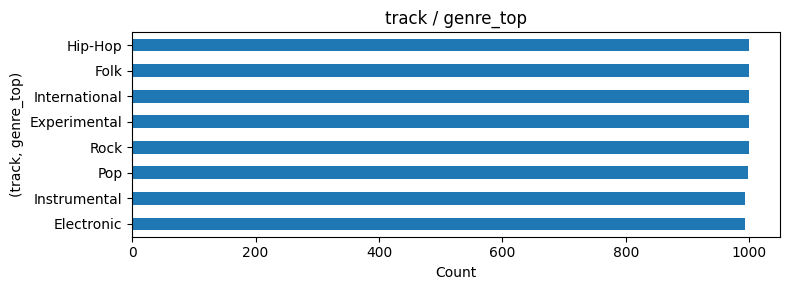

=== set / split (missing: 0 / 0.0%) ===
(set, split)
training      0.801
validation    0.100
test          0.099
Name: proportion, dtype: float64



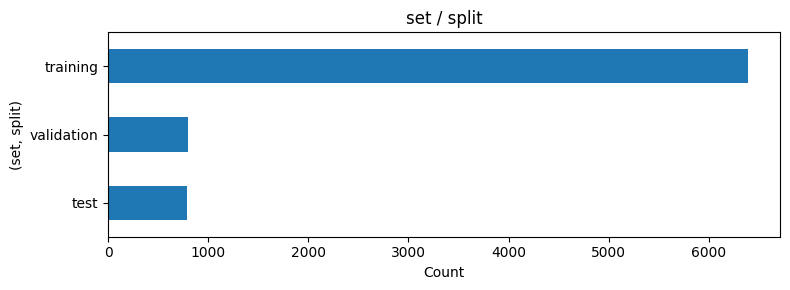

In [ ]:
# Categorical: Target Label & Dataset Split
cat_cols = [
    ('track', 'genre_top'),
    ('set', 'split'),
]

for col in cat_cols:
    print(f"=== {' / '.join(col)} (missing: {clean_tracks[col].isna().sum()} / {clean_tracks[col].isna().mean()*100:.1f}%) ===")
    print(clean_tracks[col].value_counts(normalize=True).round(3).head(15))
    print()
    clean_tracks[col].value_counts().head(15).plot.barh(figsize=(8, 3))
    plt.title(" / ".join(col))
    plt.xlabel("Count")
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.show()

**Observations (V.1):**
- **`track / genre_top`**: All 8 top-level genres are virtually balanced at ~12.4–12.5% each (0 missing values, 0 rare levels), making this an ideal multi-class classification target that requires no resampling or class-weight adjustments.
- **`set / split`**: The official benchmark partition is cleanly divided into 80.1% `training`, 10.0% `validation`, and 9.9% `test` (0 missing values), providing a standardized split for model training, hyperparameter tuning, and unbiased evaluation.

## **V.2 Audio File Technical Context (`clean_tracks`)**

Inspects `track / bit_rate` (since MP3 compression can alter high-frequency spectral features) and `track / duration` (confirming original track lengths before FMA's 30-second audio clipping).

count        mean        std       min       25%       50%  \
track bit_rate  7983.0  265391.509  60903.055  105237.0  214011.5  262289.0   
      duration  7983.0     228.849     98.432      60.0     161.0     215.0   

                     75%       max   skew  
track bit_rate  320000.0  322541.0 -0.722  
      duration     279.0     600.0  0.940

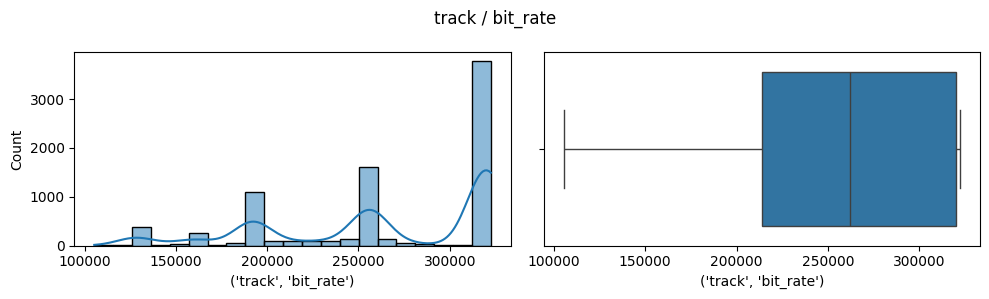

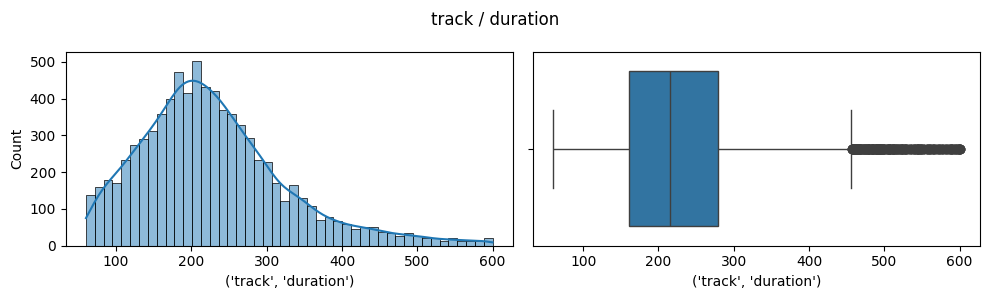

In [ ]:
# Numeric: Audio File Technical Context
num_cols = [
    ('track', 'bit_rate'),
    ('track', 'duration'),
]

display(clean_tracks[num_cols].describe().T.assign(skew=clean_tracks[num_cols].skew()).round(3))

for col in num_cols:
    fig, axes = plt.subplots(1, 2, figsize=(10, 3))
    sns.histplot(clean_tracks[col], kde=True, ax=axes[0])
    sns.boxplot(x=clean_tracks[col], ax=axes[1])
    fig.suptitle(" / ".join(col))
    plt.tight_layout()
    plt.show()

**Observations (V.2):**
- **`track / bit_rate`**: Bit rate is moderately left-skewed (`skew = -0.72`), clustering near standard high-quality MP3 encodings with a median of 262.3 kbps (mean = 265.4 kbps, SD = 60.9 kbps, IQR = 106.0 kbps from 214.0 to 320.0 kbps). Values span 105.2 to 322.5 kbps with zero IQR outliers and discrete spikes at standard bit rates (128, 192, 256, and 320 kbps), meaning most tracks have high enough audio quality to preserve upper-frequency spectral features.
- **`track / duration`**: Full track duration is moderately right-skewed (`skew = 0.94`); the median of 215 s (~3.6 min; IQR = 118 s, 161–279 s) is a slightly better summary of center than the mean of 228.8 s (SD = 98.4 s). All cleaned tracks are at least 60 s long (well above FMA-Small's 30 s clip length), with 270 upper-tail outliers (3.4%) extending up to 600 s.

## **V.3 Spectral Shape & Brightness (`clean_features`)**

Examines primary `mean / 01` frequency-domain descriptors: `spectral_centroid` (brightness), `spectral_bandwidth` (frequency spread), `spectral_rolloff` (high-frequency cutoff), and `spectral_contrast` (peak-to-valley spectral separation).

,,,count,mean,std,min,25%,50%,75%,max,skew
feature,statistics,number,,,,,,,,,
spectral_centroid,mean,01,7983.0,1175.064,501.726,140.754,818.903,1125.441,1460.532,5575.108,1.038
spectral_bandwidth,mean,01,7983.0,1420.851,440.942,241.755,1119.570,1410.866,1700.045,3789.372,0.316
spectral_rolloff,mean,01,7983.0,2371.575,1112.917,167.247,1566.877,2262.460,3041.472,9401.771,0.796
spectral_contrast,mean,01,7983.0,20.587,3.392,10.350,18.274,20.262,22.533,38.504,0.675


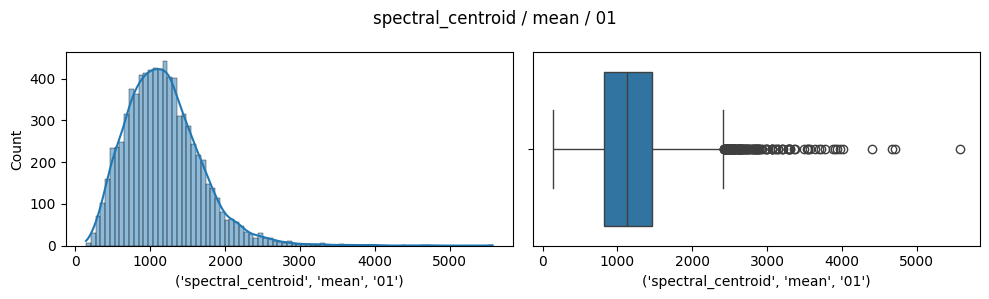

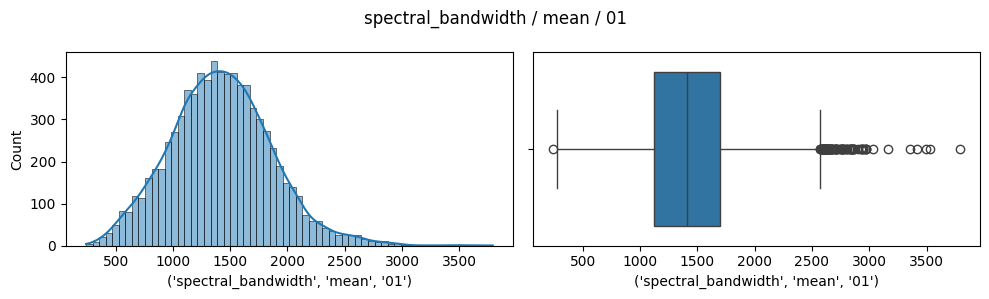

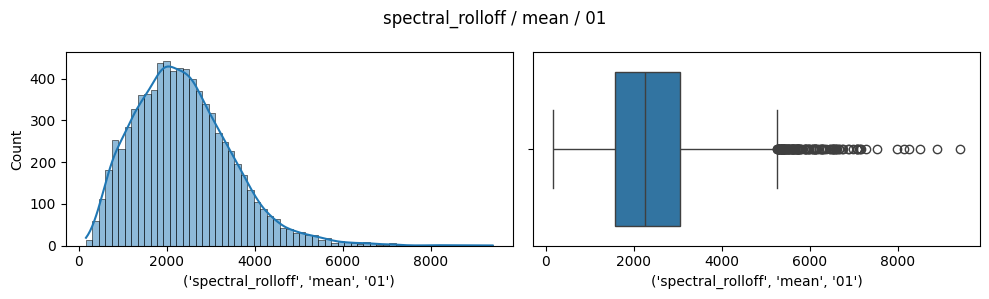

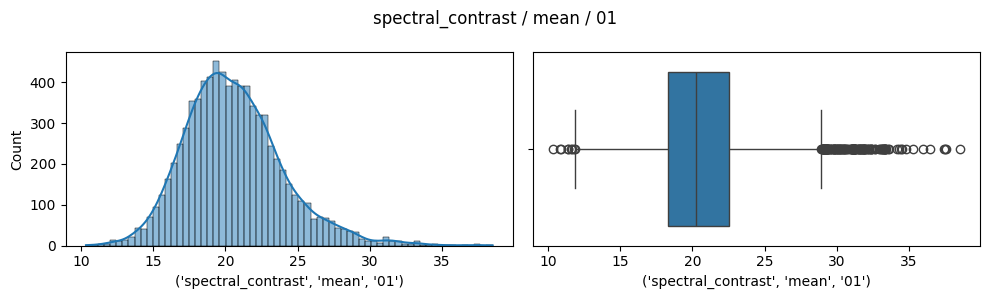

In [ ]:
# Numeric: Spectral Shape & Brightness
num_cols = [
    ('spectral_centroid', 'mean', '01'),
    ('spectral_bandwidth', 'mean', '01'),
    ('spectral_rolloff', 'mean', '01'),
    ('spectral_contrast', 'mean', '01'),
]

display(clean_features[num_cols].describe().T.assign(skew=clean_features[num_cols].skew()).round(3))

for col in num_cols:
    fig, axes = plt.subplots(1, 2, figsize=(10, 3))
    sns.histplot(clean_features[col], kde=True, ax=axes[0])
    sns.boxplot(x=clean_features[col], ax=axes[1])
    fig.suptitle(" / ".join(col))
    plt.tight_layout()
    plt.show()

**Observations (V.3):**
- **`spectral_centroid / mean / 01`**: Mean spectral centroid is heavily right-skewed (`skew = 1.04`); the median of 1,125.4 Hz (IQR = 641.6 Hz) is slightly more robust than the mean of 1,175.1 Hz (SD = 501.7 Hz). Values span 140.8 to 5,575.1 Hz with 152 upper-tail outliers (1.9%) reflecting unusually bright, high-frequency tracks.
- **`spectral_bandwidth / mean / 01`**: Mean spectral bandwidth is approximately symmetric (`skew = 0.32`), so the mean (1,420.9 Hz, SD = 440.9 Hz) and median (1,410.9 Hz, IQR = 580.5 Hz) agree closely. Values range from 241.8 to 3,789.4 Hz with only 93 IQR outliers (1.2%, nearly all upper-tail).
- **`spectral_rolloff / mean / 01`**: Mean spectral rolloff is moderately right-skewed (`skew = 0.80`), with a median of 2,262.5 Hz (IQR = 1,474.6 Hz) slightly below the mean of 2,371.6 Hz (SD = 1,112.9 Hz). Values span 167.2 to 9,401.8 Hz, including 132 upper-tail outliers (1.7%) driven by high-frequency content.
- **`spectral_contrast / mean / 01`**: Mean spectral contrast is moderately right-skewed (`skew = 0.67`), centered around a median of 20.26 (IQR = 4.26) and a mean of 20.59 (SD = 3.39). Values range from 10.35 to 38.50 with 158 IQR outliers (2.0%; 9 low, 149 high), marking tracks with sharper harmonic peaks relative to background noise.

## **V.4 Timbre / MFCCs (`clean_features`)**

Inspects the first four Mel-Frequency Cepstral Coefficient means (`mfcc / mean / 01`–`04`), which capture overall spectral energy (`01`) and the core timbral spectral envelope (`02`–`04`)—typically the highest-importance feature family in music genre classification.

count     mean     std      min      25%      50%  \
feature statistics number                                                       
mfcc    mean       01      7983.0 -202.492  93.799 -985.114 -258.302 -191.371   
                   02      7983.0  146.495  31.802  -18.084  126.392  146.334   
                   03      7983.0  -11.212  29.901 -146.494  -30.105  -12.393   
                   04      7983.0   30.264  17.185  -68.000   21.173   31.741   

                               75%      max   skew  
feature statistics number                           
mfcc    mean       01     -136.644  138.372 -0.680  
                   02      166.384  268.769 -0.056  
                   03        6.250  117.980  0.218  
                   04       41.250  125.015 -0.661

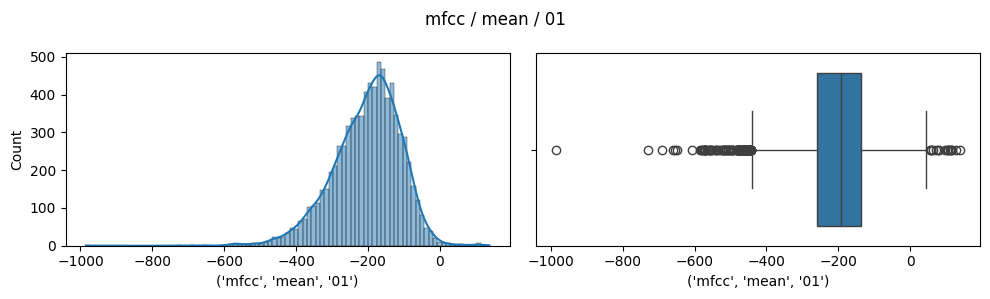

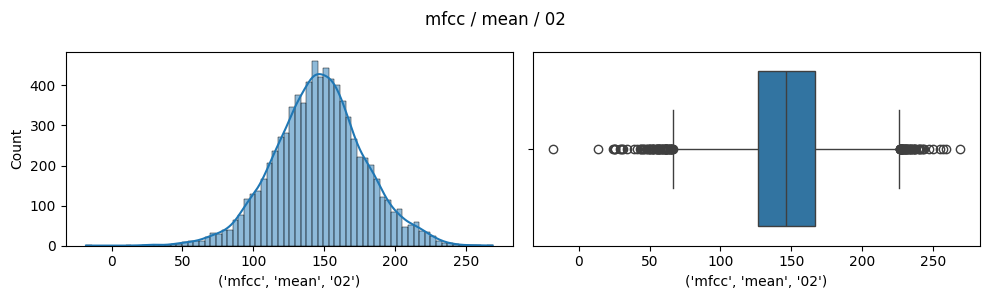

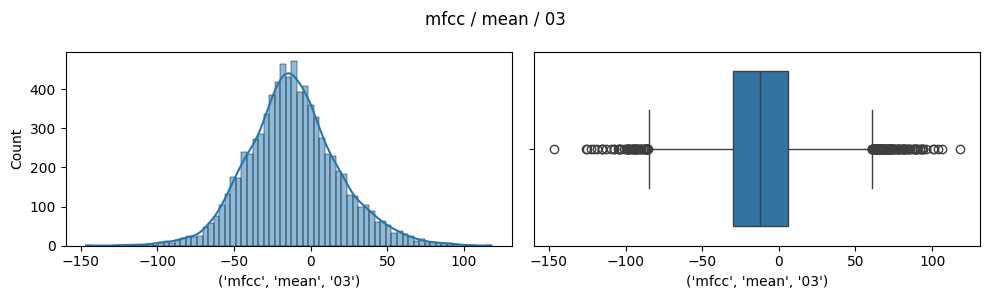

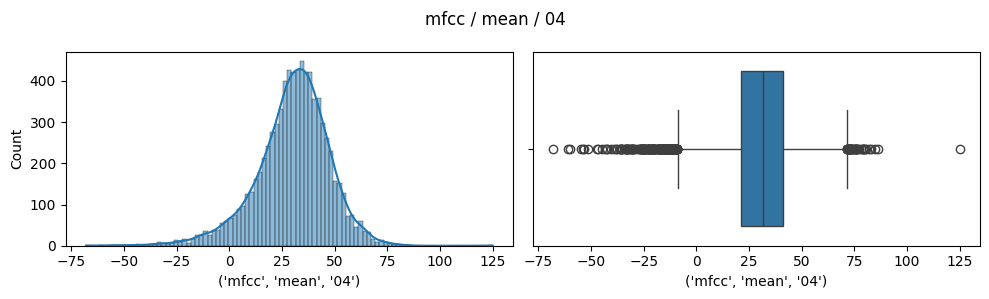

In [ ]:
# Numeric: Timbre / MFCCs
num_cols = [
    ('mfcc', 'mean', '01'),
    ('mfcc', 'mean', '02'),
    ('mfcc', 'mean', '03'),
    ('mfcc', 'mean', '04'),
]

display(clean_features[num_cols].describe().T.assign(skew=clean_features[num_cols].skew()).round(3))

for col in num_cols:
    fig, axes = plt.subplots(1, 2, figsize=(10, 3))
    sns.histplot(clean_features[col], kde=True, ax=axes[0])
    sns.boxplot(x=clean_features[col], ax=axes[1])
    fig.suptitle(" / ".join(col))
    plt.tight_layout()
    plt.show()

**Observations (V.4):**
- **`mfcc / mean / 01`**: The first MFCC mean (overall spectral energy) is moderately left-skewed (`skew = -0.68`); the median of -191.4 (IQR = 121.7) is slightly higher than the mean of -202.5 (SD = 93.8). Values span -985.1 to 138.4 with 131 IQR outliers (1.6%; 114 low, 17 high), where extreme negative values correspond to quiet or sparse audio.
- **`mfcc / mean / 02`**: The second MFCC mean (broad low-to-high spectral slope) is nearly symmetric (`skew = -0.06`), with virtually identical mean (146.5, SD = 31.8) and median (146.3, IQR = 40.0). Values range from -18.1 to 268.8 with only 122 balanced IQR outliers (1.5%; 69 low, 53 high).
- **`mfcc / mean / 03`**: The third MFCC mean is approximately symmetric (`skew = 0.22`), centered near -12.4 (median; IQR = 36.4) and -11.2 (mean; SD = 29.9). Values span -146.5 to 118.0 with 185 IQR outliers (2.3%; 64 low, 121 high).
- **`mfcc / mean / 04`**: The fourth MFCC mean is moderately left-skewed (`skew = -0.66`); the median of 31.7 (IQR = 20.1) is slightly above the mean of 30.3 (SD = 17.2). Values span -68.0 to 125.0 with 254 IQR outliers (3.2%; 214 low, 40 high), showing a heavier lower tail than `mfcc 02` and `03`.

## **V.5 Energy, Percussion & Harmony (`clean_features`)**

Evaluates loudness (`rmse`), percussiveness/noisiness (`zcr`), pitch-class energy (`chroma_cens`), and tonal centroid (`tonnetz`) via their primary `mean / 01` descriptors.

,,,count,mean,std,min,25%,50%,75%,max,skew
feature,statistics,number,,,,,,,,,
rmse,mean,01,7983.0,4.565,2.478,0.000,2.734,4.283,6.008,21.608,1.336
zcr,mean,01,7983.0,0.051,0.028,0.003,0.032,0.046,0.063,0.630,3.477
chroma_cens,mean,01,7983.0,0.251,0.082,0.004,0.200,0.250,0.299,0.706,0.368
tonnetz,mean,01,7983.0,0.001,0.014,-0.095,-0.006,0.001,0.009,0.077,0.020


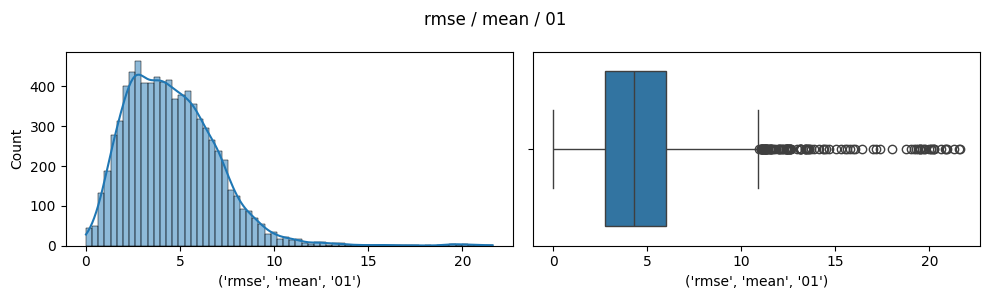

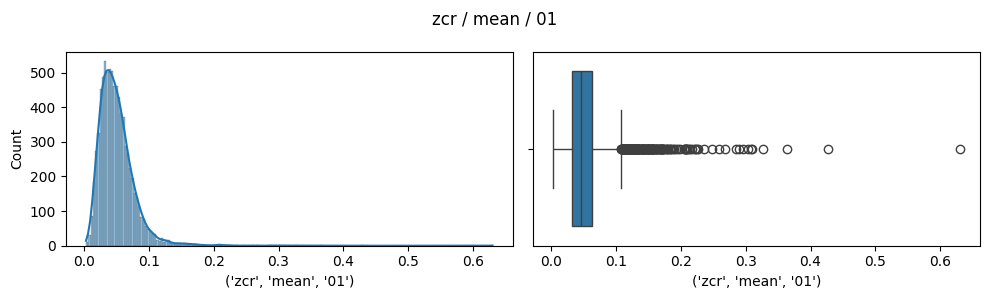

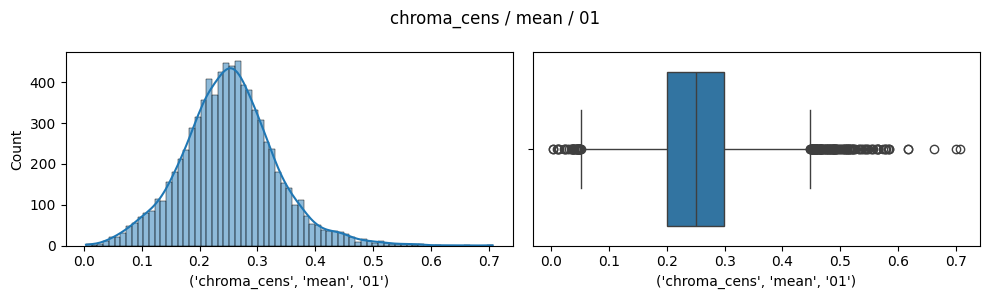

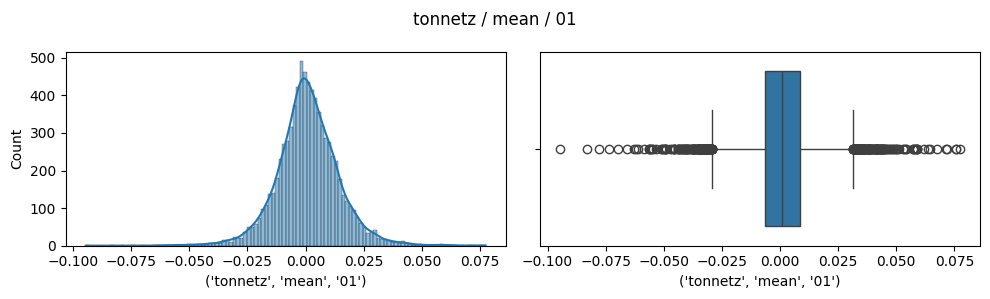

In [ ]:
# Numeric: Energy, Percussion & Harmony
num_cols = [
    ('rmse', 'mean', '01'),
    ('zcr', 'mean', '01'),
    ('chroma_cens', 'mean', '01'),
    ('tonnetz', 'mean', '01'),
]

display(clean_features[num_cols].describe().T.assign(skew=clean_features[num_cols].skew()).round(3))

for col in num_cols:
    fig, axes = plt.subplots(1, 2, figsize=(10, 3))
    sns.histplot(clean_features[col], kde=True, ax=axes[0])
    sns.boxplot(x=clean_features[col], ax=axes[1])
    fig.suptitle(" / ".join(col))
    plt.tight_layout()
    plt.show()

**Observations (V.5):**
- **`rmse / mean / 01`**: Mean root-mean-square energy (loudness) is heavily right-skewed (`skew = 1.34`), with a median of 4.28 (IQR = 3.27) below the mean of 4.57 (SD = 2.48). Values span near-silence (0.000) to 21.61, with 113 upper-tail outliers (1.4%) representing unusually loud or heavily compressed tracks.
- **`zcr / mean / 01`**: Mean zero-crossing rate is heavily right-skewed (`skew = 3.48`); the median of 0.046 (IQR = 0.030) is a better summary than the mean of 0.051 (SD = 0.028). Values extend from 0.003 to 0.630 with 244 upper-tail outliers (3.1%) marking highly percussive, distorted, or noisy audio.
- **`chroma_cens / mean / 01`**: Mean chroma energy is approximately symmetric (`skew = 0.37`), with closely matching mean (0.251, SD = 0.082) and median (0.250, IQR = 0.099). It spans 0.004 to 0.706 with 183 IQR outliers (2.3%; 41 low, 142 high).
- **`tonnetz / mean / 01`**: Mean tonal centroid is tightly symmetric around zero (`skew = 0.02`; mean = 0.001, median = 0.001, SD = 0.014, IQR = 0.015). Despite clean centering, it shows moderately heavy tails with 280 symmetric IQR outliers (3.5%; 138 low, 142 high) spanning -0.095 to 0.077.

## **V.6 Temporal Variability (`clean_features`)**

Inspects frame-level standard deviation (`std / 01`) across loudness, spectral brightness, noisiness, and timbre to capture how much a track's acoustic properties fluctuate across its 30-second clip.

,,,count,mean,std,min,25%,50%,75%,max,skew
feature,statistics,number,,,,,,,,,
rmse,std,01,7983.0,2.197,1.023,0.000,1.435,2.077,2.820,8.914,0.768
spectral_centroid,std,01,7983.0,604.842,278.979,55.690,400.998,569.971,758.585,3023.301,1.126
zcr,std,01,7983.0,0.040,0.026,0.003,0.023,0.034,0.051,0.318,2.080
mfcc,std,01,7983.0,82.711,22.171,8.798,67.493,81.895,96.674,236.649,0.347


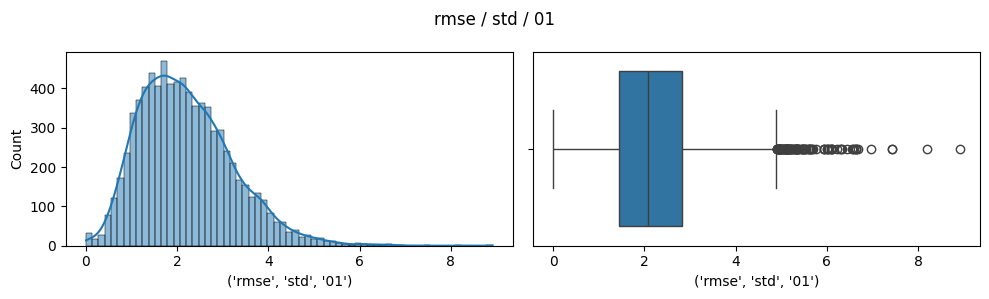

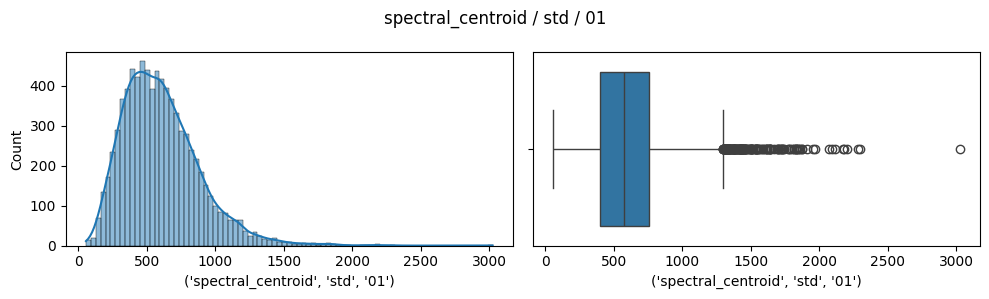

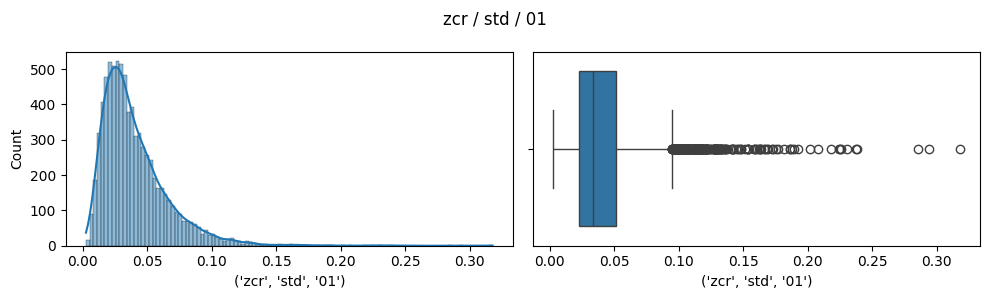

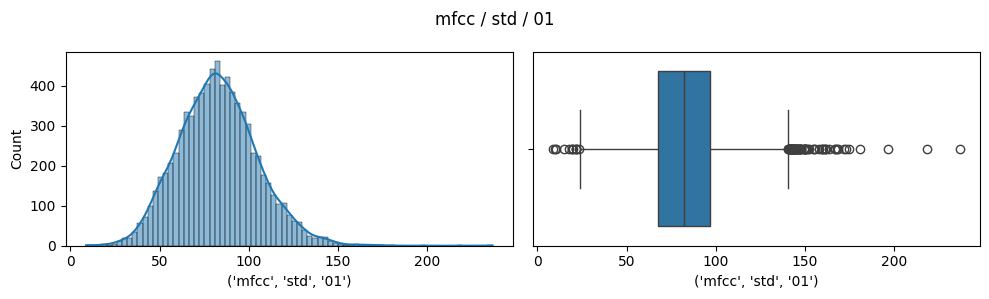

In [ ]:
# Numeric: Temporal Variability (std)
num_cols = [
    ('rmse', 'std', '01'),
    ('spectral_centroid', 'std', '01'),
    ('zcr', 'std', '01'),
    ('mfcc', 'std', '01'),
]

display(clean_features[num_cols].describe().T.assign(skew=clean_features[num_cols].skew()).round(3))

for col in num_cols:
    fig, axes = plt.subplots(1, 2, figsize=(10, 3))
    sns.histplot(clean_features[col], kde=True, ax=axes[0])
    sns.boxplot(x=clean_features[col], ax=axes[1])
    fig.suptitle(" / ".join(col))
    plt.tight_layout()
    plt.show()

**Observations (V.6):**
- **`rmse / std / 01`**: Loudness variability is moderately right-skewed (`skew = 0.77`), with a median of 2.08 (IQR = 1.39) slightly below the mean of 2.20 (SD = 1.02). Values span 0.000 to 8.91 with 105 upper-tail outliers (1.3%), distinguishing tracks with sharp dynamic swings from steadily compressed tracks.
- **`spectral_centroid / std / 01`**: Brightness variability is heavily right-skewed (`skew = 1.13`); the median of 570.0 Hz (IQR = 357.6 Hz) is a better summary than the mean of 604.8 Hz (SD = 279.0 Hz). Values range from 55.7 to 3,023.3 Hz with 167 upper-tail outliers (2.1%) reflecting abrupt timbral shifts.
- **`zcr / std / 01`**: Zero-crossing rate variability is heavily right-skewed (`skew = 2.08`); the median of 0.034 (IQR = 0.029) better represents typical tracks than the mean of 0.040 (SD = 0.026). Values reach up to 0.318 with 310 upper-tail outliers (3.9%), capturing intermittent bursts of percussion or noise.
- **`mfcc / std / 01`**: First-MFCC variability is approximately symmetric (`skew = 0.35`), with closely matching mean (82.7, SD = 22.2) and median (81.9, IQR = 29.2). Values span 8.8 to 236.6 with only 88 IQR outliers (1.1%; 12 low, 76 high).

---

### **Key Takeaways for Audio-Feature Data Mining**
- **No Class-Imbalance Correction Needed**: `track / genre_top` is evenly balanced across all 8 genres (~12.5% each), and `set / split` provides a ready-to-use 80/10/10 benchmark partition.
- **Feature Scaling Is Essential**: Audio features span **6 orders of magnitude**—from `tonnetz / mean / 01` (~0.001) and `zcr / mean / 01` (~0.05) up to `spectral_rolloff / mean / 01` (~2,372)—so distance-, margin-, and gradient-based models (KNN, SVM, Logistic Regression, Neural Networks, PCA) require `StandardScaler` or `RobustScaler`.
- **Right-Skewed Features & Outliers**: Several acoustic predictors (`zcr`, `rmse`, `spectral_centroid`, and their `std` counterparts) exhibit right-skewness (`skew = 1.0–3.5`) with 1–4% upper-tail outliers; tree-based models (Random Forest, Gradient Boosting/XGBoost) handle these natively, while linear/distance-based models will benefit from power/log transforms or robust scaling.

# **VI. Bivariate, Multivariate & Data Mining Analysis**

This section moves from bivariate exploration of the cleaned FMA-Small dataset (`clean_tracks` and `clean_features`) into supervised and unsupervised data mining on the 518 `librosa` audio features. It is organized in two parts—starting with split, correlation, and genre-profile checks (**VI.1–VI.3**), followed by **Logistic Regression**, **Random Forest**, and **Hierarchical Clustering** (**VI.4–VI.5**):

- **VI.1 Technical Confound & Split Stratification Check (`clean_tracks`)** — Verifies genre balance across the official `training`, `validation`, and `test` splits and checks whether `bit_rate` or `duration` vary by genre.
- **VI.2 Feature-to-Feature Correlation & Multicollinearity (`clean_features`)** — Audits pairwise correlations across the 16 representative descriptors and multicollinearity across all 518 audio features.
- **VI.3 Acoustic Feature Profiles Across Genres (`clean_features` × `genre_top`)** — Compares standardized genre acoustic profiles (z-score heatmap) and distributions of the top contrasting descriptors.
- **VI.4 Music Genre Classification & Feature Importance: Logistic Regression vs. Random Forest** — Trains and evaluates both supervised classifiers on the official splits and ranks audio feature families, summary statistics, and top descriptors.
- **VI.5 Unsupervised Acoustic Structure via Hierarchical Clustering (`clean_features`)** — Uses Ward hierarchical clustering to map genre-level acoustic similarity (dendrogram) and compare unsupervised track clusters ($k = 8$) against true genres.

## **VI.1 Technical Confound & Split Stratification Check (`clean_tracks`)**

Verifies that genre balance holds across the official `training`, `validation`, and `test` splits (`track / genre_top` × `set / split`), and tests whether technical file attributes (`track / bit_rate` and `track / duration`) vary systematically by genre—which would signal non-acoustic confounds if left unchecked.

=== Genre x Official Split Contingency Table ===


"(set, split)",training,validation,test,Total
"(track, genre_top)",,,,
Electronic,798,100,95,993
Experimental,799,100,100,999
Folk,800,100,100,1000
Hip-Hop,800,100,100,1000
Instrumental,797,100,97,994
International,800,100,100,1000
Pop,798,100,100,998
Rock,799,100,100,999


Chi-square test of independence: chi2 = 0.219, dof = 14, p = 1.0000

=== Bit Rate (kbps) medians by genre (Kruskal-Wallis H=424.43, p=1.37e-87, eta2_H=0.0523) ===
genre
Electronic       320.0
Hip-Hop          320.0
Instrumental     320.0
Pop              265.2
Experimental     259.6
Folk             256.0
International    256.0
Rock             256.0 

=== Original Track Duration (s) medians by genre (Kruskal-Wallis H=285.62, p=7.09e-58, eta2_H=0.0349) ===
genre
Electronic       243.0
International    239.0
Folk             222.0
Pop              214.0
Rock             213.0
Experimental     208.0
Hip-Hop          201.0
Instrumental     190.0 



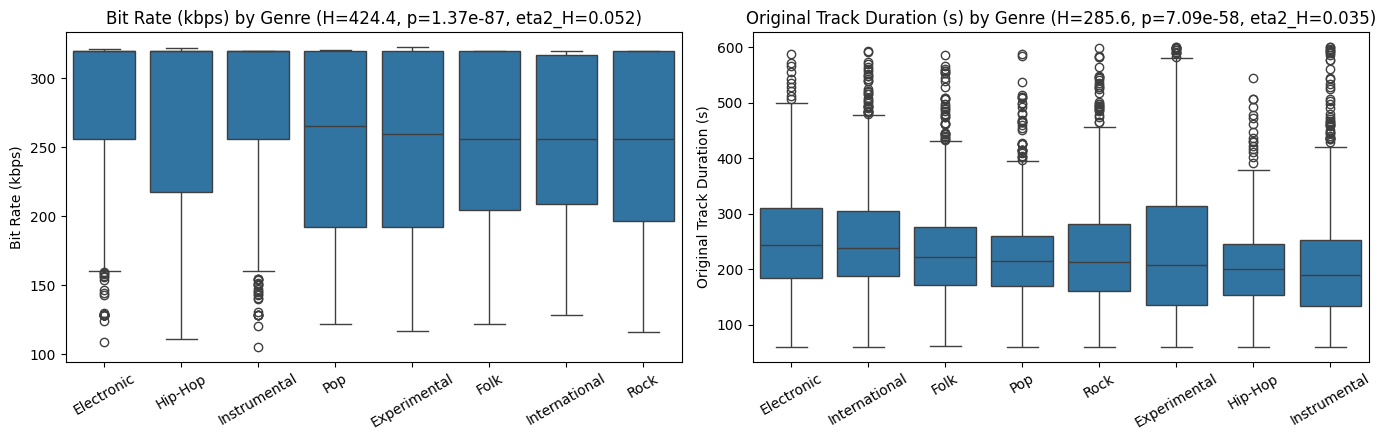

In [ ]:
# VI.1 Split Stratification & Technical Confound Check
genre = clean_tracks[('track', 'genre_top')]
split = clean_tracks[('set', 'split')]

# 1. Contingency table: Genre vs. Official Split
ct = pd.crosstab(genre, split)[['training', 'validation', 'test']]
chi2, p_chi2, dof, _ = stats.chi2_contingency(ct)
print("=== Genre x Official Split Contingency Table ===")
display(ct.assign(Total=ct.sum(axis=1)))
print(f"Chi-square test of independence: chi2 = {chi2:.3f}, dof = {dof}, p = {p_chi2:.4f}\n")

# 2. Technical attributes across genres (Kruskal-Wallis + Boxplots)
tech_cols = [('track', 'bit_rate'), ('track', 'duration')]
tech_df = pd.DataFrame({
    'genre': genre,
    'bit_rate_kbps': clean_tracks[('track', 'bit_rate')] / 1000.0,
    'duration_sec': clean_tracks[('track', 'duration')],
})

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, (col_name, label) in zip(axes, [('bit_rate_kbps', 'Bit Rate (kbps)'), ('duration_sec', 'Original Track Duration (s)')]):
    groups = [grp[col_name].values for _, grp in tech_df.groupby('genre')]
    H, p_kw = stats.kruskal(*groups)
    n = len(tech_df)
    k = len(groups)
    eta2_h = max(0.0, (H - k + 1) / (n - k))
    order = tech_df.groupby('genre')[col_name].median().sort_values(ascending=False).index
    sns.boxplot(data=tech_df, x='genre', y=col_name, order=order, ax=ax)
    ax.set_title(f"{label} by Genre (H={H:.1f}, p={p_kw:.2e}, eta2_H={eta2_h:.3f})")
    ax.set_xlabel("")
    ax.set_ylabel(label)
    ax.tick_params(axis='x', rotation=30)
    medians = tech_df.groupby('genre')[col_name].median().loc[order].round(1)
    print(f"=== {label} medians by genre (Kruskal-Wallis H={H:.2f}, p={p_kw:.2e}, eta2_H={eta2_h:.4f}) ===")
    print(medians.to_string(), "\n")

plt.tight_layout()
plt.show()

**Observations (VI.1):**
- **Split Stratification (`genre_top` × `set / split`)**: Class balance remains intact across all three partitions after removing the 17 duplicate rows—797–800 `training`, exactly 100 `validation`, and 95–100 `test` tracks per genre ($\chi^2 = 0.219$, $\text{dof} = 14$, $p = 1.0000$). No resampling or re-splitting is needed.
- **Bit Rate Confound (`track / bit_rate` by genre)**: Bit rate differs significantly across genres with a small-to-moderate effect ($H = 424.43$, $p = 1.37 \times 10^{-87}$, $\eta^2_H = 0.052$). Electronic, Hip-Hop, and Instrumental tracks have a higher median encoding (320.0 kbps) than Folk, International, and Rock (256.0 kbps). While all genre medians are $\ge 256$ kbps (preserving most audible high-frequency content), this confirms **`bit_rate` must be excluded from model features** to prevent encoding-bias leakage.
- **Original Duration (`track / duration` by genre)**: Full track length varies modestly by genre ($H = 285.62$, $p = 7.09 \times 10^{-58}$, $\eta^2_H = 0.035$), with Electronic (243 s) and International (239 s) longest and Instrumental (190 s) and Hip-Hop (201 s) shortest. Excluding `duration` keeps classification strictly anchored on the standardized 30-second `librosa` audio features.

## **VI.2 Feature-to-Feature Correlation & Multicollinearity (`clean_features`)**

Inspects pairwise relationships among the 16 representative audio features from Section V (using Spearman rank correlation to handle skewness and outliers robustly), and audits redundancy across all 518 `librosa` descriptors to diagnose multicollinearity before feature selection and modeling.

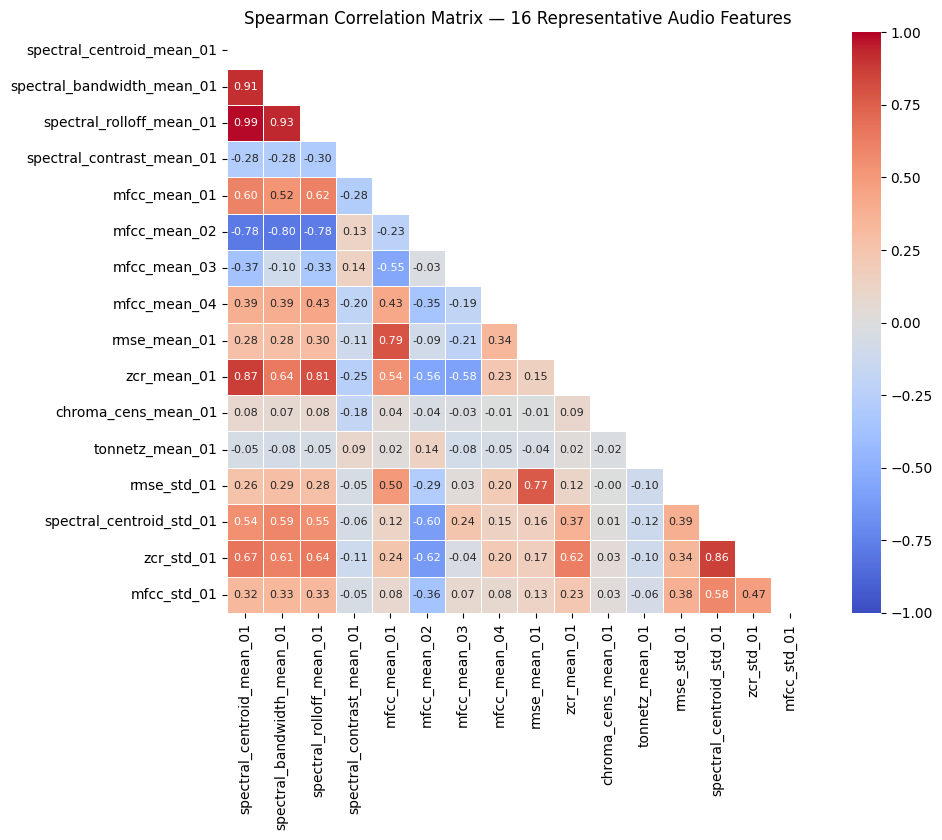

=== Top 10 Strongest Pairwise Correlations (16 Representative Features, Spearman) ===


,Feature A,Feature B,spearman_r
1,spectral_centroid_mean_01,spectral_rolloff_mean_01,0.988
15,spectral_bandwidth_mean_01,spectral_rolloff_mean_01,0.935
0,spectral_centroid_mean_01,spectral_bandwidth_mean_01,0.915
8,spectral_centroid_mean_01,zcr_mean_01,0.868
117,spectral_centroid_std_01,zcr_std_01,0.860
35,spectral_rolloff_mean_01,zcr_mean_01,0.811
18,spectral_bandwidth_mean_01,mfcc_mean_02,-0.795
57,mfcc_mean_01,rmse_mean_01,0.792
4,spectral_centroid_mean_01,mfcc_mean_02,-0.783
31,spectral_rolloff_mean_01,mfcc_mean_02,-0.780



=== Full 518-Feature Multicollinearity Audit (Pearson |r|) ===
Total unique feature pairs : 133,903
Pairs with |r| >= 0.85     : 248 (0.19%)
Pairs with |r| >= 0.90     : 164 (0.12%)
Pairs with |r| >= 0.95     : 80 (0.06%)
Features with >=1 partner at |r| >= 0.85: 204 / 518 (39.4%)

=== Features with at Least One |r| >= 0.85 Partner, by Feature Family ===


,total_features,collinear_features_r85,pct_collinear
feature,,,
spectral_centroid,7,5,71.4
spectral_rolloff,7,5,71.4
chroma_stft,84,50,59.5
spectral_bandwidth,7,4,57.1
chroma_cqt,84,37,44.0
zcr,7,3,42.9
rmse,7,3,42.9
mfcc,140,47,33.6
chroma_cens,84,24,28.6


In [ ]:
# VI.2 Feature-to-Feature Correlation & Full-Dataset Multicollinearity Audit
rep_cols = [
    ('spectral_centroid', 'mean', '01'),
    ('spectral_bandwidth', 'mean', '01'),
    ('spectral_rolloff', 'mean', '01'),
    ('spectral_contrast', 'mean', '01'),
    ('mfcc', 'mean', '01'),
    ('mfcc', 'mean', '02'),
    ('mfcc', 'mean', '03'),
    ('mfcc', 'mean', '04'),
    ('rmse', 'mean', '01'),
    ('zcr', 'mean', '01'),
    ('chroma_cens', 'mean', '01'),
    ('tonnetz', 'mean', '01'),
    ('rmse', 'std', '01'),
    ('spectral_centroid', 'std', '01'),
    ('zcr', 'std', '01'),
    ('mfcc', 'std', '01'),
]
rep_labels = [f"{a}_{b}_{c}" for a, b, c in rep_cols]
rep_df = clean_features[rep_cols].copy()
rep_df.columns = rep_labels

# 1. Spearman correlation heatmap of the 16 representative features
corr_spearman = rep_df.corr(method='spearman')
mask = np.triu(np.ones_like(corr_spearman, dtype=bool))

plt.figure(figsize=(11, 8.5))
sns.heatmap(
    corr_spearman,
    mask=mask,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.4,
    annot_kws={'size': 8},
)
plt.title("Spearman Correlation Matrix — 16 Representative Audio Features")
plt.tight_layout()
plt.show()

# Top correlated pairs among representative features
upper_rep = corr_spearman.where(np.triu(np.ones(corr_spearman.shape), k=1).astype(bool))
rep_pairs = (
    upper_rep.stack()
    .rename('spearman_r')
    .reset_index()
    .rename(columns={'level_0': 'Feature A', 'level_1': 'Feature B'})
)
rep_pairs['abs_r'] = rep_pairs['spearman_r'].abs()
print("=== Top 10 Strongest Pairwise Correlations (16 Representative Features, Spearman) ===")
display(rep_pairs.sort_values('abs_r', ascending=False).head(10)[['Feature A', 'Feature B', 'spearman_r']].round(3))

# 2. Full 518-feature multicollinearity audit (Pearson |r|)
full_corr = clean_features.corr(method='pearson').abs()
upper_mask = np.triu(np.ones(full_corr.shape, dtype=bool), k=1)
vals = full_corr.values[upper_mask]
total_pairs = len(vals)
n_85 = int((vals >= 0.85).sum())
n_90 = int((vals >= 0.90).sum())
n_95 = int((vals >= 0.95).sum())

# Features involved in at least one |r| >= 0.85 pair
adj = (full_corr.values >= 0.85).copy()
np.fill_diagonal(adj, False)
features_with_collinear = int(adj.any(axis=1).sum())

print(f"\n=== Full 518-Feature Multicollinearity Audit (Pearson |r|) ===")
print(f"Total unique feature pairs : {total_pairs:,}")
print(f"Pairs with |r| >= 0.85     : {n_85:,} ({n_85 / total_pairs * 100:.2f}%)")
print(f"Pairs with |r| >= 0.90     : {n_90:,} ({n_90 / total_pairs * 100:.2f}%)")
print(f"Pairs with |r| >= 0.95     : {n_95:,} ({n_95 / total_pairs * 100:.2f}%)")
print(f"Features with >=1 partner at |r| >= 0.85: {features_with_collinear} / {clean_features.shape[1]} ({features_with_collinear / clean_features.shape[1] * 100:.1f}%)")

# Breakdown of highly collinear features by feature family
families = clean_features.columns.get_level_values(0)
fam_summary = pd.DataFrame({
    'total_features': pd.Series(families).value_counts(),
    'collinear_features_r85': pd.Series(families[adj.any(axis=1)]).value_counts(),
}).fillna(0).astype(int)
fam_summary['pct_collinear'] = (fam_summary['collinear_features_r85'] / fam_summary['total_features'] * 100).round(1)
print("\n=== Features with at Least One |r| >= 0.85 Partner, by Feature Family ===")
display(fam_summary.sort_values('pct_collinear', ascending=False))

**Observations (VI.2):**
- **Tight Spectral-Brightness Cluster**: `spectral_centroid / mean / 01`, `spectral_rolloff / mean / 01`, and `spectral_bandwidth / mean / 01` are nearly collinear ($\rho = 0.915\text{–}0.988$), and also correlate strongly with `zcr / mean / 01` ($\rho = 0.811\text{–}0.868$); their temporal variabilities (`spectral_centroid / std / 01` and `zcr / std / 01`) move together similarly ($\rho = 0.860$).
- **Meaningful Cross-Family Acoustic Links**: `mfcc / mean / 01` tracks loudness (`rmse / mean / 01`, $\rho = 0.792$), while `mfcc / mean / 02` (spectral slope) inversely tracks brightness and bandwidth ($\rho = -0.780$ to $-0.795$). By contrast, tonal/harmonic descriptors (`chroma_cens` and `tonnetz`) remain largely orthogonal to the spectral/loudness block, contributing independent musical information.
- **Substantial Redundancy Across All 518 Features**: Nearly **40% of all descriptors (204 / 518)** share $|r| \ge 0.85$ with at least one other feature (248 pairs at $|r| \ge 0.85$, 80 pairs at $|r| \ge 0.95$), concentrated most heavily in `spectral_centroid` (71.4%), `spectral_rolloff` (71.4%), `chroma_stft` (59.5%), and `spectral_bandwidth` (57.1%). For data mining, this means regularized models (Ridge/Lasso/SVM), PCA, or feature pruning are advisable—and individual tree importances may split credit across correlated siblings.

## **VI.3 Acoustic Feature Profiles Across Genres (`clean_features` × `genre_top`)**

Compares the 16 representative audio features across the 8 genres using standardized genre means (z-score profiles ordered by across-genre spread) and genre-wise boxplots for the most contrasting descriptors.

=== Across-Genre Z-Score Spread Across 16 Representative Features ===


,Feature,Z_Spread_Max_Minus_Min,Highest_Genre,Lowest_Genre
0,mfcc_mean_01,1.573,Rock,Instrumental
1,spectral_bandwidth_mean_01,1.531,Electronic,Instrumental
2,mfcc_mean_03,1.503,Instrumental,Rock
3,spectral_rolloff_mean_01,1.495,Electronic,Instrumental
4,spectral_centroid_mean_01,1.399,Electronic,Instrumental
5,rmse_std_01,1.283,Hip-Hop,Instrumental
6,mfcc_mean_02,1.279,Instrumental,Electronic
7,mfcc_mean_04,1.133,Hip-Hop,Instrumental
8,rmse_mean_01,1.004,Hip-Hop,Instrumental
9,spectral_centroid_std_01,0.986,Electronic,Rock


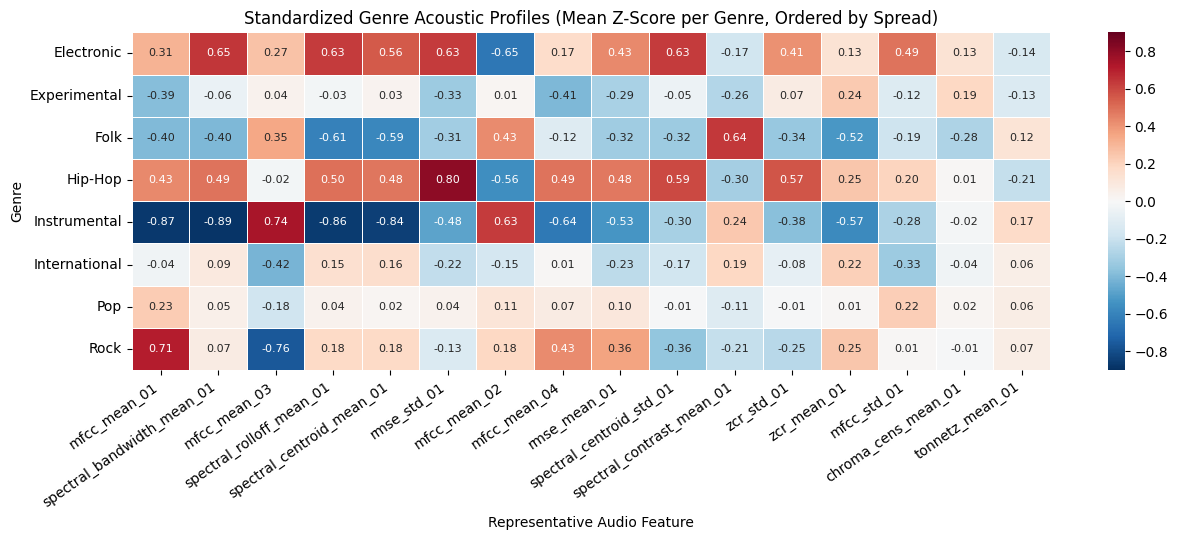

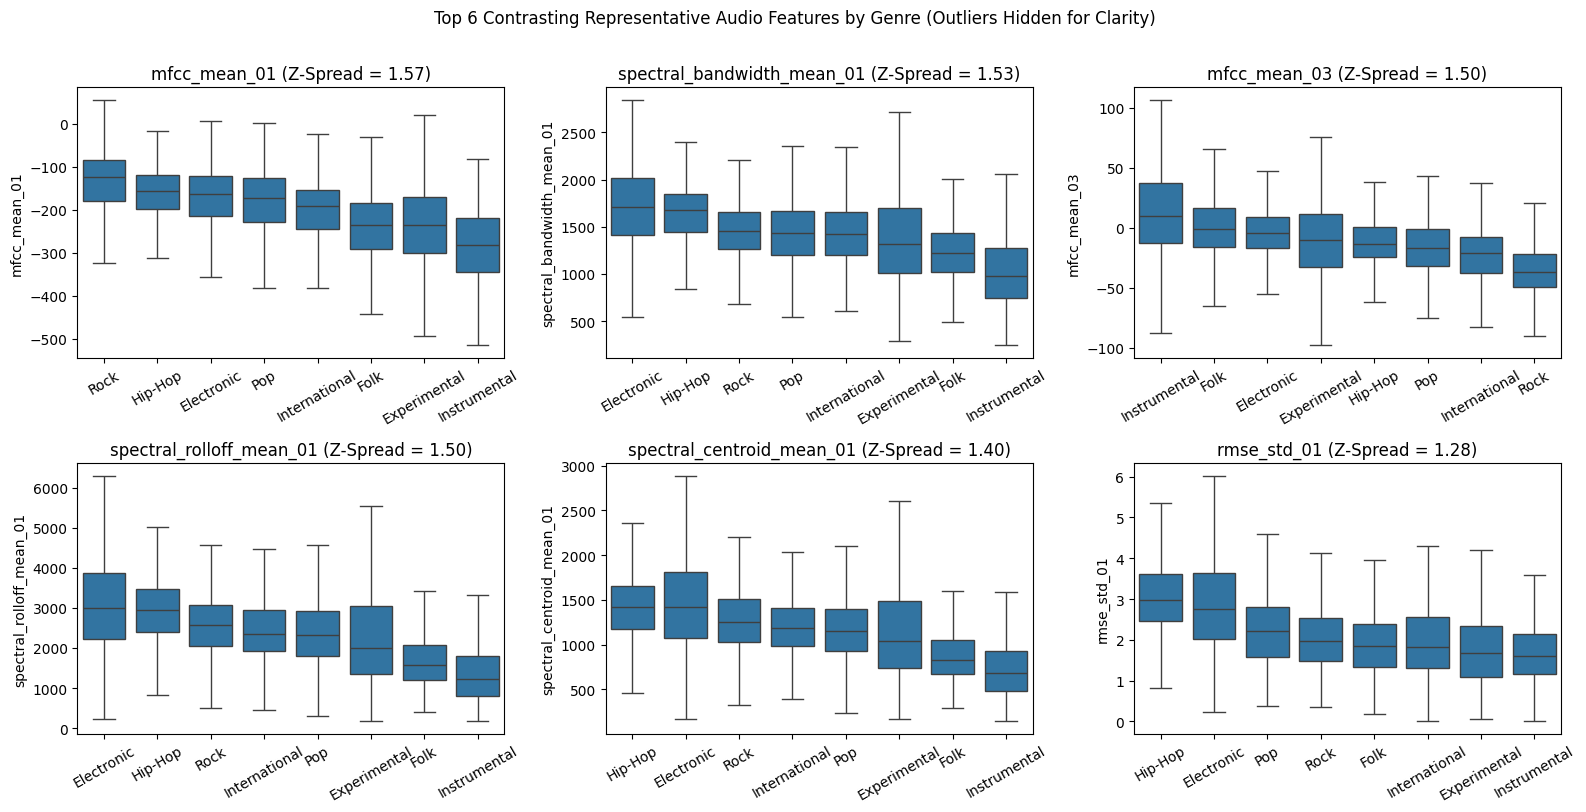

In [11]:
# VI.3 Acoustic Feature Profiles Across Genres (Standardized Means & Distributions)
rep_cols = [
    ('spectral_centroid', 'mean', '01'),
    ('spectral_bandwidth', 'mean', '01'),
    ('spectral_rolloff', 'mean', '01'),
    ('spectral_contrast', 'mean', '01'),
    ('mfcc', 'mean', '01'),
    ('mfcc', 'mean', '02'),
    ('mfcc', 'mean', '03'),
    ('mfcc', 'mean', '04'),
    ('rmse', 'mean', '01'),
    ('zcr', 'mean', '01'),
    ('chroma_cens', 'mean', '01'),
    ('tonnetz', 'mean', '01'),
    ('rmse', 'std', '01'),
    ('spectral_centroid', 'std', '01'),
    ('zcr', 'std', '01'),
    ('mfcc', 'std', '01'),
]
rep_labels = [f"{a}_{b}_{c}" for a, b, c in rep_cols]
rep_df = clean_features[rep_cols].copy()
rep_df.columns = rep_labels
genre = clean_tracks[('track', 'genre_top')]

# 1. Standardized (z-score) genre acoustic profile ordered by across-genre z-score spread
z_rep = (rep_df - rep_df.mean()) / rep_df.std()
z_rep['genre'] = genre.values
genre_profile = z_rep.groupby('genre')[rep_labels].mean()
spread = (genre_profile.max() - genre_profile.min()).sort_values(ascending=False)
genre_profile = genre_profile[spread.index]

spread_df = pd.DataFrame({
    'Feature': spread.index,
    'Z_Spread_Max_Minus_Min': spread.values.round(3),
    'Highest_Genre': [genre_profile[f].idxmax() for f in spread.index],
    'Lowest_Genre': [genre_profile[f].idxmin() for f in spread.index],
})
print("=== Across-Genre Z-Score Spread Across 16 Representative Features ===")
display(spread_df)

plt.figure(figsize=(13, 5.5))
sns.heatmap(
    genre_profile,
    annot=True,
    fmt='.2f',
    cmap='RdBu_r',
    center=0,
    vmin=-0.9,
    vmax=0.9,
    linewidths=0.4,
    annot_kws={'size': 8},
)
plt.title("Standardized Genre Acoustic Profiles (Mean Z-Score per Genre, Ordered by Spread)")
plt.xlabel("Representative Audio Feature")
plt.ylabel("Genre")
plt.xticks(rotation=35, ha='right')
plt.tight_layout()
plt.show()

# 2. Boxplots for the top 6 most contrasting representative features
top6_feats = spread.head(6).index.tolist()
plot_df = rep_df[top6_feats].copy()
plot_df['genre'] = genre.values

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, feat in zip(axes.flat, top6_feats):
    order = plot_df.groupby('genre')[feat].median().sort_values(ascending=False).index
    sns.boxplot(data=plot_df, x='genre', y=feat, order=order, showfliers=False, ax=ax)
    ax.set_title(f"{feat} (Z-Spread = {spread[feat]:.2f})")
    ax.set_xlabel("")
    ax.tick_params(axis='x', rotation=30)

plt.suptitle("Top 6 Contrasting Representative Audio Features by Genre (Outliers Hidden for Clarity)", y=1.01)
plt.tight_layout()
plt.show()

**Observations (VI.3):**
- **Largest Across-Genre Contrasts**: Overall spectral energy, spectral width/brightness, low-order timbre, and loudness variability separate genres most clearly—led by `mfcc / mean / 01` (z-spread `1.573`), `spectral_bandwidth / mean / 01` (`1.531`), `mfcc / mean / 03` (`1.503`), `spectral_rolloff / mean / 01` (`1.495`), `spectral_centroid / mean / 01` (`1.399`), and `rmse / std / 01` (`1.283`). By contrast, single pitch-class harmonic features (`tonnetz / mean / 01`: `0.380`; `chroma_cens / mean / 01`: `0.466`) vary little across genres because pitch-class peaks depend on musical key rather than genre.
- **Distinct Genre Acoustic Fingerprints**:
  - **Instrumental & Folk**: Darker, lower-energy profiles with lower spectral rolloff, centroid, bandwidth, and loudness variability.
  - **Electronic & Hip-Hop**: High spectral brightness/bandwidth paired with strong dynamic variability (`rmse / std / 01`).
  - **Rock**: Highest overall loudness (`mfcc / mean / 01`) and lowest `mfcc / mean / 03`, reflecting sustained, compressed instrumentation.
- **Overlapping Genres**: **Pop**, **International**, and **Experimental** sit closer to the dataset mean across individual descriptors, showing why multivariate data mining classifiers across all 518 audio features are necessary.

## **VI.4 Music Genre Classification & Feature Importance: Logistic Regression vs. Random Forest**

Trains and evaluates two complementary supervised data mining classifiers strictly on the 518 `librosa` audio features (`clean_features`) using FMA's official leakage-free `training` (6,391), `validation` (800), and `test` (792) splits:
- **Logistic Regression** (standardized inputs with L2 regularization tuned on `validation` to handle Section VI.2's multicollinearity)
- **Random Forest** (300-tree non-linear ensemble)

Both models are compared on `validation` and `test` Accuracy, Macro-F1, per-genre F1, and normalized confusion matrices, and used to quantify which **audio feature families**, **summary statistics**, and **individual descriptors** drive genre classification.

Split sizes -> Training: 6,391, Validation: 800, Test: 792
Selected Logistic Regression regularization: C = 0.01 (Validation Macro-F1 = 0.5348)

=== Classification Performance Summary (Official Splits, All 518 Audio Features) ===


,Model,Val_Accuracy,Val_Macro_F1,Test_Accuracy,Test_Macro_F1
0,"Logistic Regression (L2, C=0.01)",0.5437,0.5348,0.4545,0.4528
1,Random Forest (300 trees),0.5487,0.5313,0.4899,0.4900



=== Per-Genre Test F1-Score Comparison ===


,"Logistic Regression (L2, C=0.01)",Random Forest (300 trees)
Electronic,0.583,0.597
Experimental,0.365,0.267
Folk,0.155,0.242
Hip-Hop,0.696,0.654
Instrumental,0.391,0.462
International,0.484,0.560
Pop,0.346,0.459
Rock,0.603,0.680


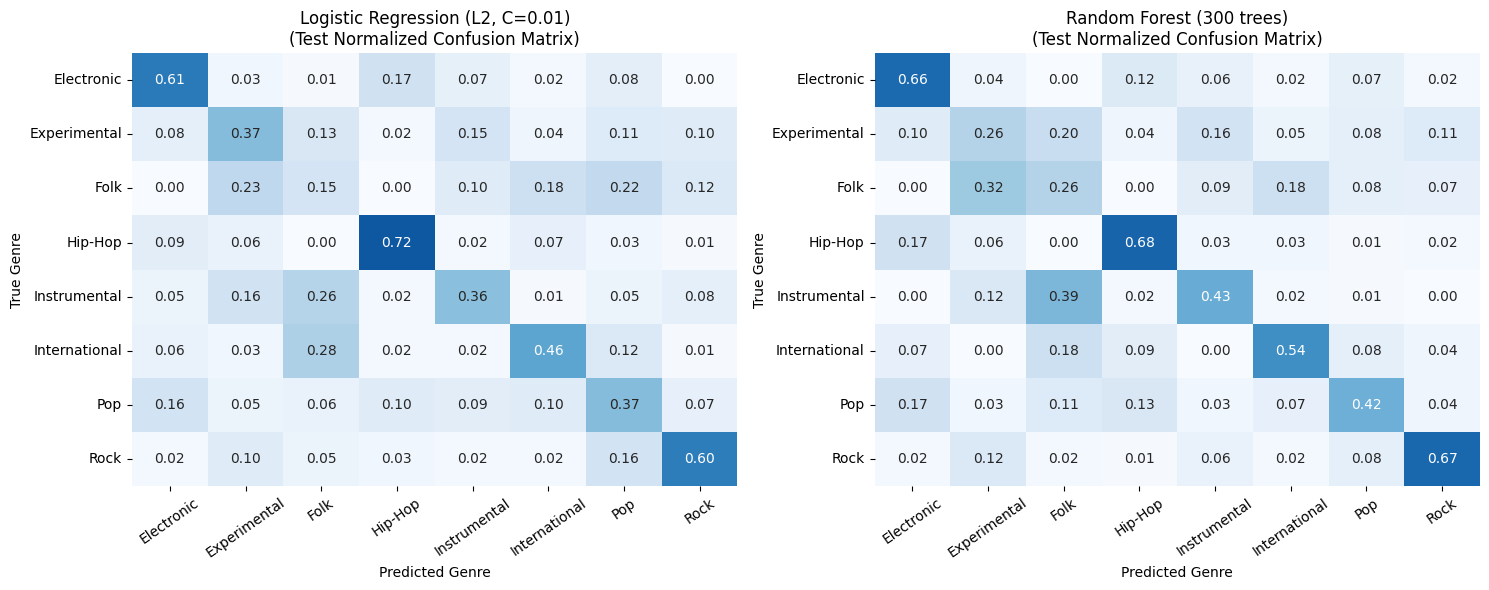


=== Audio Feature-Family Importance (Random Forest vs. Logistic Regression) ===


,n_features,rf_total_pct,lr_total_pct,rf_mean_x1e3
family,,,,
mfcc,140,34.35,32.29,2.45
spectral_contrast,49,13.88,12.44,2.83
chroma_stft,84,11.75,11.82,1.40
chroma_cens,84,10.95,12.73,1.30
chroma_cqt,84,10.23,13.79,1.22
tonnetz,42,7.86,7.99,1.87
spectral_rolloff,7,2.44,1.39,3.48
spectral_centroid,7,2.43,1.40,3.47
spectral_bandwidth,7,2.17,2.15,3.10



=== Summary-Statistic Importance (Random Forest vs. Logistic Regression) ===


,n_features,rf_total_pct,lr_total_pct
stat,,,
std,74,18.08,18.76
median,74,17.27,12.47
mean,74,17.13,11.74
skew,74,13.60,14.63
kurtosis,74,12.57,13.99
min,74,10.77,13.90
max,74,10.59,14.51



=== Top 15 Individual Audio Features by Random Forest Importance ===


,feature_name,family,stat,rf_importance,lr_importance
0,mfcc / mean / 03,mfcc,mean,0.00654,0.00325
1,mfcc / max / 04,mfcc,max,0.00654,0.00744
2,mfcc / median / 03,mfcc,median,0.00632,0.00284
3,spectral_rolloff / median / 01,spectral_rolloff,median,0.00629,0.00259
4,spectral_contrast / median / 04,spectral_contrast,median,0.00611,0.00283
5,mfcc / mean / 01,mfcc,mean,0.00600,0.00448
6,spectral_centroid / mean / 01,spectral_centroid,mean,0.00596,0.00139
7,spectral_contrast / mean / 04,spectral_contrast,mean,0.00586,0.00273
8,rmse / std / 01,rmse,std,0.00578,0.00389
9,spectral_centroid / median / 01,spectral_centroid,median,0.00568,0.00193


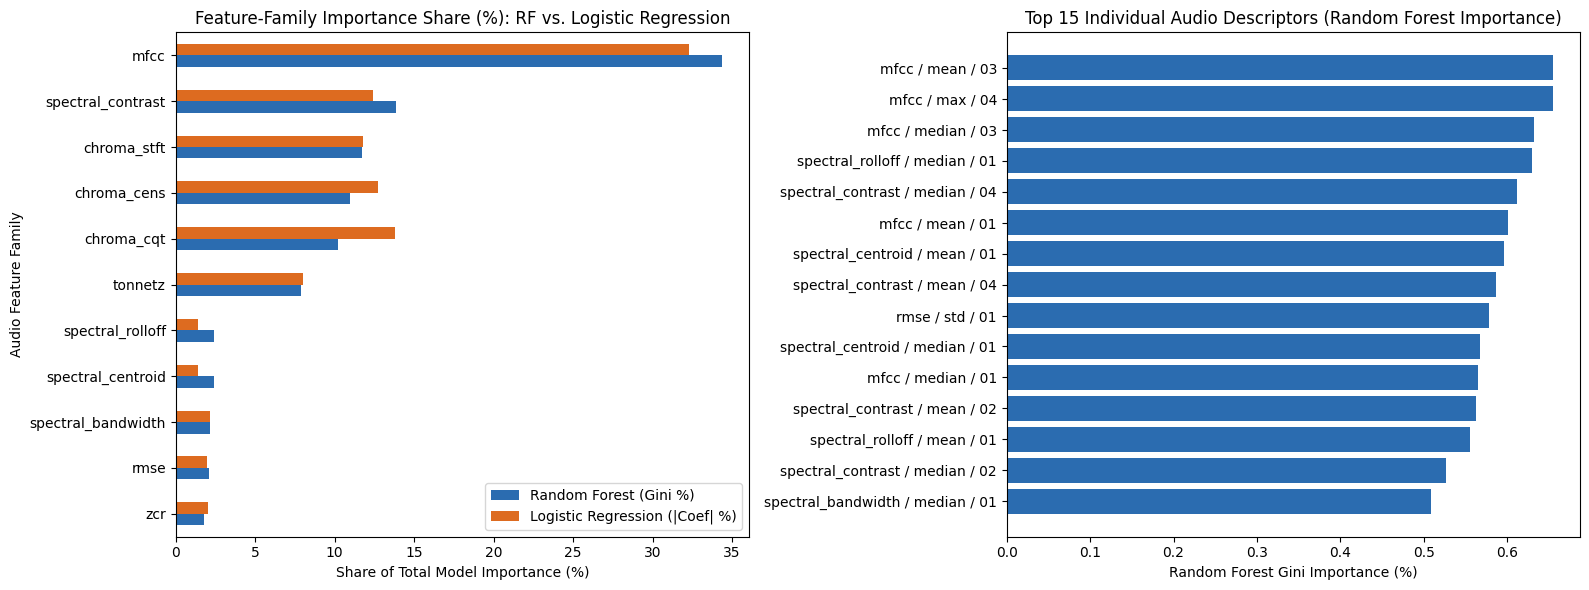

In [12]:
# VI.4 Music Genre Classification & Feature Importance: Logistic Regression vs. Random Forest
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

# 1. Official leakage-free partition (training / validation / test)
split_col = clean_tracks[('set', 'split')]
y_all = clean_tracks[('track', 'genre_top')]
genres = sorted(y_all.unique())

train_mask = split_col == 'training'
val_mask = split_col == 'validation'
test_mask = split_col == 'test'

X_train, y_train = clean_features.loc[train_mask], y_all.loc[train_mask]
X_val, y_val = clean_features.loc[val_mask], y_all.loc[val_mask]
X_test, y_test = clean_features.loc[test_mask], y_all.loc[test_mask]

print(f"Split sizes -> Training: {len(X_train):,}, Validation: {len(X_val):,}, Test: {len(X_test):,}")

# 2. Model 1: Regularized Logistic Regression (select L2 C on validation split)
best_lr, best_c, best_val_f1 = None, None, -1.0
for c_val in [0.005, 0.01, 0.05, 0.1, 1.0]:
    pipe = Pipeline([
        ('scaler', StandardScaler()),
        ('clf', LogisticRegression(C=c_val, max_iter=1000, random_state=42)),
    ])
    pipe.fit(X_train, y_train)
    val_f1 = f1_score(y_val, pipe.predict(X_val), average='macro')
    if val_f1 > best_val_f1:
        best_val_f1, best_c, best_lr = val_f1, c_val, pipe

print(f"Selected Logistic Regression regularization: C = {best_c} (Validation Macro-F1 = {best_val_f1:.4f})")

# 3. Model 2: Random Forest Classifier
rf_clf = RandomForestClassifier(n_estimators=300, max_features='sqrt', random_state=42, n_jobs=-1)
rf_clf.fit(X_train, y_train)

# 4. Evaluate both models on Validation and Test splits
models = {
    f'Logistic Regression (L2, C={best_c})': best_lr,
    'Random Forest (300 trees)': rf_clf,
}

results = []
test_preds = {}
per_genre_f1 = pd.DataFrame(index=genres)
for name, model in models.items():
    val_pred = model.predict(X_val)
    test_pred = model.predict(X_test)
    test_preds[name] = test_pred
    results.append({
        'Model': name,
        'Val_Accuracy': round(accuracy_score(y_val, val_pred), 4),
        'Val_Macro_F1': round(f1_score(y_val, val_pred, average='macro'), 4),
        'Test_Accuracy': round(accuracy_score(y_test, test_pred), 4),
        'Test_Macro_F1': round(f1_score(y_test, test_pred, average='macro'), 4),
    })
    rep = classification_report(y_test, test_pred, labels=genres, output_dict=True)
    per_genre_f1[name] = [round(rep[g]['f1-score'], 3) for g in genres]

results_df = pd.DataFrame(results)
print("\n=== Classification Performance Summary (Official Splits, All 518 Audio Features) ===")
display(results_df)
print("\n=== Per-Genre Test F1-Score Comparison ===")
display(per_genre_f1)

# 5. Side-by-side Normalized Confusion Matrices on the Test Split
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, (name, pred) in zip(axes, test_preds.items()):
    cm = confusion_matrix(y_test, pred, labels=genres, normalize='true')
    sns.heatmap(cm, annot=True, fmt='.2f', cmap='Blues', xticklabels=genres, yticklabels=genres,
                vmin=0, vmax=0.85, cbar=False, ax=ax)
    ax.set_title(f"{name}\n(Test Normalized Confusion Matrix)")
    ax.set_xlabel("Predicted Genre")
    ax.set_ylabel("True Genre")
    ax.tick_params(axis='x', rotation=35)
plt.tight_layout()
plt.show()

# 6. Audio Feature Importance (Random Forest Gini & Logistic Regression Mean |Coef|)
rf_imp = rf_clf.feature_importances_
lr_coef_abs = np.abs(best_lr.named_steps['clf'].coef_).mean(axis=0)
lr_imp_share = lr_coef_abs / lr_coef_abs.sum()

imp_df = pd.DataFrame({
    'feature_name': [' / '.join(c) for c in X_train.columns],
    'family': [c[0] for c in X_train.columns],
    'stat': [c[1] for c in X_train.columns],
    'rf_importance': rf_imp,
    'lr_importance': lr_imp_share,
})

# Save Series for Section VII.3 band-by-band analysis
rf_imp_series = pd.Series(rf_imp, index=X_train.columns)

fam_imp = imp_df.groupby('family').agg(
    n_features=('feature_name', 'count'),
    rf_total_pct=('rf_importance', lambda s: s.sum() * 100),
    lr_total_pct=('lr_importance', lambda s: s.sum() * 100),
    rf_mean_x1e3=('rf_importance', lambda s: s.mean() * 1000),
).sort_values('rf_total_pct', ascending=False)

stat_imp = imp_df.groupby('stat').agg(
    n_features=('feature_name', 'count'),
    rf_total_pct=('rf_importance', lambda s: s.sum() * 100),
    lr_total_pct=('lr_importance', lambda s: s.sum() * 100),
).sort_values('rf_total_pct', ascending=False)

print("\n=== Audio Feature-Family Importance (Random Forest vs. Logistic Regression) ===")
display(fam_imp.round(2))
print("\n=== Summary-Statistic Importance (Random Forest vs. Logistic Regression) ===")
display(stat_imp.round(2))
print("\n=== Top 15 Individual Audio Features by Random Forest Importance ===")
display(imp_df.sort_values('rf_importance', ascending=False).head(15)[['feature_name', 'family', 'stat', 'rf_importance', 'lr_importance']].round(5).reset_index(drop=True))

# 7. Visualize Feature-Family Share & Top 15 Audio Features
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

fam_plot = fam_imp[['rf_total_pct', 'lr_total_pct']].iloc[::-1]
fam_plot.plot(kind='barh', ax=axes[0], color=['#2b6cb0', '#dd6b20'])
axes[0].set_title("Feature-Family Importance Share (%): RF vs. Logistic Regression")
axes[0].set_xlabel("Share of Total Model Importance (%)")
axes[0].set_ylabel("Audio Feature Family")
axes[0].legend(['Random Forest (Gini %)', 'Logistic Regression (|Coef| %)'], loc='lower right')

top15 = imp_df.sort_values('rf_importance', ascending=False).head(15).iloc[::-1]
axes[1].barh(top15['feature_name'], top15['rf_importance'] * 100, color='#2b6cb0')
axes[1].set_title("Top 15 Individual Audio Descriptors (Random Forest Importance)")
axes[1].set_xlabel("Random Forest Gini Importance (%)")

plt.tight_layout()
plt.show()

**Observations (VI.4):**
- **Model Performance (Official Splits, Random Chance = 12.5%)**:
  - **Random Forest (300 trees)** achieves the strongest generalization on the held-out test split with **48.99% Test Accuracy** and **0.4900 Test Macro-F1** (Validation: **54.87%** Accuracy / **0.5313** Macro-F1), outperforming **Logistic Regression (L2, $C=0.01$)** (**45.45%** Test Accuracy / **0.4528** Test Macro-F1; Validation: **54.37%** / **0.5348**) by **+3.54 percentage points** in Test Accuracy.
  - Both models achieve roughly **3.6× to 3.9× random chance** using audio features alone, matching published FMA-Small tabular benchmarks.
- **Per-Genre Strengths & Confusions**:
  - The cleanest acoustic classes on `test` are **Rock** (RF F1 = `0.680`, LR = `0.603`), **Hip-Hop** (LR = `0.696`, RF = `0.654`), and **Electronic** (RF = `0.597`, LR = `0.583`), followed by **International** (RF = `0.560`), **Instrumental** (RF = `0.462`), and **Pop** (RF = `0.459`).
  - **Folk** (RF = `0.242`, LR = `0.155`) and **Experimental** (LR = `0.365`, RF = `0.267`) remain the hardest classes on `test` due to acoustic overlap with neighboring genres and artist-disjoint evaluation.
- **Audio Feature Importance Across Both Models**:
  - **Timbre (`mfcc`) and Spectral Contrast Dominate**: By total model share, **`mfcc`** leads in both Random Forest (**34.35%**) and Logistic Regression (**32.29%**), followed by **`spectral_contrast`** (**13.88%** RF, **12.44%** LR)—jointly contributing **48.23%** of all Random Forest split importance.
  - **Highest Per-Feature Signal Density**: Compact 7-feature spectral and energy families pack the highest average importance per descriptor (`spectral_rolloff`: `3.48×10⁻³`, `spectral_centroid`: `3.47×10⁻³`, `spectral_bandwidth`: `3.10×10⁻³`, `rmse`: `3.03×10⁻³`), whereas `chroma_*` families derive their total share mostly from having 84 features each (`1.22–1.40×10⁻³` per feature).
  - **Summary Statistics**: Temporal variability (**`std`**) is the #1 statistic in **both** Random Forest (**18.08%**) and Logistic Regression (**18.76%**), and `std` + `median` + `mean` together supply **52.48%** of Random Forest importance. The Top 15 individual features are composed exclusively of `mfcc`, `spectral_contrast`, `spectral_rolloff`, `spectral_centroid`, `spectral_bandwidth`, and `rmse / std / 01`.

## **VI.5 Unsupervised Acoustic Structure via Hierarchical Clustering (`clean_features`)**

Applies **Hierarchical Clustering** (Ward linkage on standardized 518-dimensional `training` audio features) to examine natural acoustic groupings without using genre labels during clustering:
1. **Genre-Level Dendrogram** (Ward linkage on standardized genre centroids) to map acoustic proximity across the 8 genres.
2. **Track-Level Agglomerative Clustering** ($k = 8$, Ward linkage) evaluated against true genre labels using Adjusted Rand Index (ARI), Normalized Mutual Information (NMI), Cluster Purity, and a Cluster × True Genre alignment heatmap.

=== Genre-Level Hierarchical Clustering (Ward Linkage on 518-D Standardized Centroids) ===
Merge 1: Electronic  <-->  Hip-Hop  | Ward distance = 3.94
Merge 2: International  <-->  Pop  | Ward distance = 4.12
Merge 3: Folk  <-->  Instrumental  | Ward distance = 5.25
Merge 4: Experimental  <-->  (International + Pop)  | Ward distance = 5.96
Merge 5: Rock  <-->  (Experimental + (International + Pop))  | Ward distance = 8.42
Merge 6: (Electronic + Hip-Hop)  <-->  (Rock + (Experimental + (International + Pop)))  | Ward distance = 10.05
Merge 7: (Folk + Instrumental)  <-->  ((Electronic + Hip-Hop) + (Rock + (Experimental + (International + Pop))))  | Ward distance = 15.33

=== Track-Level Agglomerative Hierarchical Clustering (k = 8, Ward Linkage) ===
Adjusted Rand Index (ARI)          : 0.0789
Normalized Mutual Information (NMI): 0.1173
Overall Cluster Purity             : 28.04% (random baseline: 12.50%)


,Cluster,Size,Dominant_Genre,Dominant_Share_Pct
0,C2,207,Experimental,41.5
1,C4,1,Experimental,100.0
2,C5,1,Experimental,100.0
3,C7,1214,Folk,34.3
4,C6,1179,Hip-Hop,32.4
5,C0,1254,International,19.3
6,C1,916,International,20.6
7,C3,1619,Rock,29.3


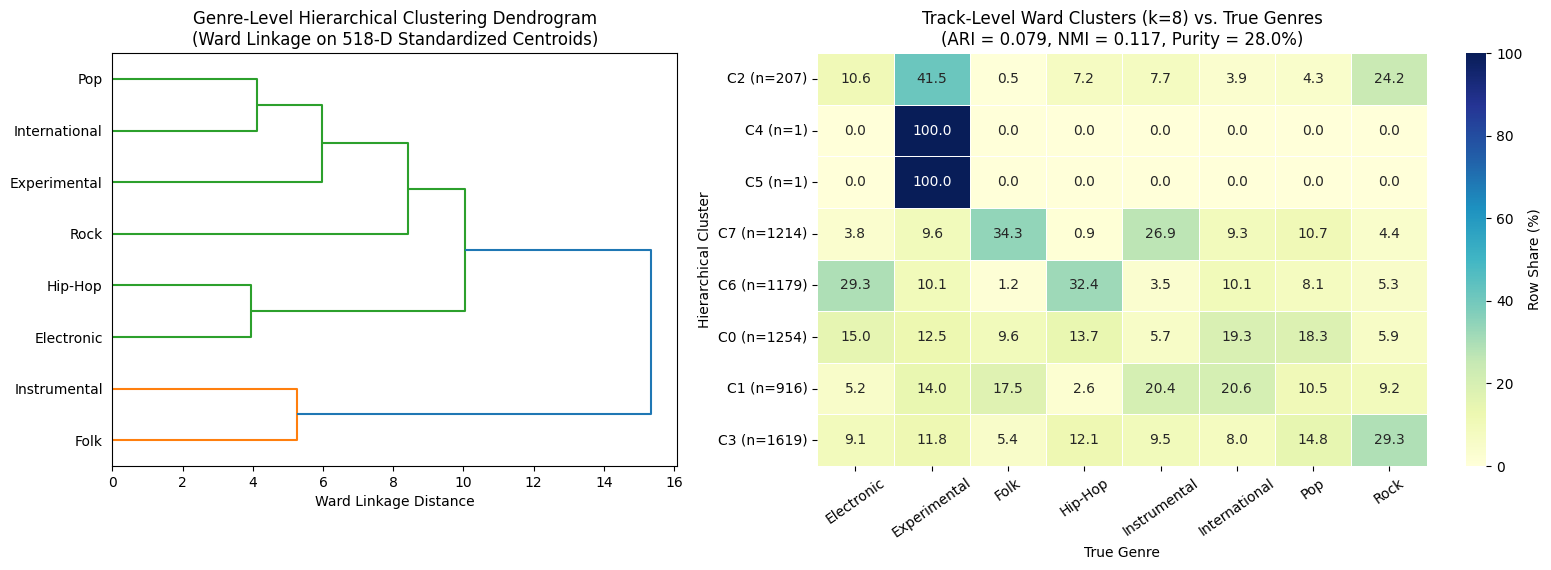

In [13]:
# VI.5 Unsupervised Acoustic Structure via Hierarchical Clustering (Training Split)
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
from scipy.cluster.hierarchy import linkage, dendrogram

train_mask = clean_tracks[('set', 'split')] == 'training'
X_train_raw = clean_features.loc[train_mask]
y_train_labels = clean_tracks.loc[train_mask, ('track', 'genre_top')]
genres = sorted(y_train_labels.unique())

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_raw)
X_train_z_df = pd.DataFrame(X_train_scaled, index=X_train_raw.index, columns=X_train_raw.columns)

# 1. Genre-level Ward Hierarchical Clustering on standardized 518-D genre centroids
genre_centroids = X_train_z_df.groupby(y_train_labels).mean().loc[genres]
Z_genre = linkage(genre_centroids.values, method='ward')

# Print pairwise centroid merge order
print("=== Genre-Level Hierarchical Clustering (Ward Linkage on 518-D Standardized Centroids) ===")
merge_labels = list(genres)
for step_idx, row in enumerate(Z_genre, start=1):
    a, b, dist, cnt = int(row[0]), int(row[1]), row[2], int(row[3])
    new_name = f"({merge_labels[a]} + {merge_labels[b]})"
    merge_labels.append(new_name)
    print(f"Merge {step_idx}: {merge_labels[a]}  <-->  {merge_labels[b]}  | Ward distance = {dist:.2f}")

# 2. Track-level Agglomerative Hierarchical Clustering (k = 8, Ward linkage)
hc = AgglomerativeClustering(n_clusters=8, linkage='ward')
cluster_ids = hc.fit_predict(X_train_scaled)

ari = adjusted_rand_score(y_train_labels, cluster_ids)
nmi = normalized_mutual_info_score(y_train_labels, cluster_ids)
ct_counts = pd.crosstab(pd.Series(cluster_ids, name='Cluster'), y_train_labels.values)
ct_counts.columns.name = 'True Genre'
purity = ct_counts.max(axis=1).sum() / len(y_train_labels)

print("\n=== Track-Level Agglomerative Hierarchical Clustering (k = 8, Ward Linkage) ===")
print(f"Adjusted Rand Index (ARI)          : {ari:.4f}")
print(f"Normalized Mutual Information (NMI): {nmi:.4f}")
print(f"Overall Cluster Purity             : {purity * 100:.2f}% (random baseline: 12.50%)")

# Order clusters by dominant genre for readable heatmap
dom_genre = ct_counts.idxmax(axis=1)
cluster_order = ct_counts.assign(_dom=dom_genre, _max=ct_counts.max(axis=1)).sort_values(['_dom', '_max'], ascending=[True, False]).index
ct_ordered = ct_counts.loc[cluster_order]
ct_pct = ct_ordered.div(ct_ordered.sum(axis=1), axis=0) * 100

summary_clusters = pd.DataFrame({
    'Cluster': [f'C{c}' for c in ct_ordered.index],
    'Size': ct_ordered.sum(axis=1).values,
    'Dominant_Genre': ct_ordered.idxmax(axis=1).values,
    'Dominant_Share_Pct': ct_pct.max(axis=1).values.round(1),
})
display(summary_clusters)

# 3. Visualize Genre Dendrogram & Track Cluster-vs-Genre Alignment Heatmap
fig, axes = plt.subplots(1, 2, figsize=(16, 5.8), gridspec_kw={'width_ratios': [1.0, 1.35]})

dendrogram(
    Z_genre,
    labels=genres,
    orientation='right',
    leaf_font_size=10,
    color_threshold=0.7 * Z_genre[:, 2].max(),
    ax=axes[0],
)
axes[0].set_title("Genre-Level Hierarchical Clustering Dendrogram\n(Ward Linkage on 518-D Standardized Centroids)")
axes[0].set_xlabel("Ward Linkage Distance")

sns.heatmap(
    ct_pct,
    annot=True,
    fmt='.1f',
    cmap='YlGnBu',
    linewidths=0.4,
    yticklabels=[f"C{c} (n={ct_ordered.loc[c].sum()})" for c in ct_ordered.index],
    cbar_kws={'label': 'Row Share (%)'},
    ax=axes[1],
)
axes[1].set_title(f"Track-Level Ward Clusters (k=8) vs. True Genres\n(ARI = {ari:.3f}, NMI = {nmi:.3f}, Purity = {purity*100:.1f}%)")
axes[1].set_xlabel("True Genre")
axes[1].set_ylabel("Hierarchical Cluster")
axes[1].tick_params(axis='x', rotation=35)

plt.tight_layout()
plt.show()

**Observations (VI.5):**
- **Three Natural Acoustic Macro-Families (Genre Dendrogram)**:
  1. **Beat-Driven / Bright Cluster**: `Electronic` and `Hip-Hop` merge first (Ward distance = `3.94`), reflecting shared spectral brightness and dynamic variability.
  2. **Vocal / Crossover / Band Cluster**: `International` and `Pop` merge next (`4.12`), joined by `Experimental` (`5.96`) and `Rock` (`8.42`), explaining the cross-genre confusions observed in Section VI.4's confusion matrices.
  3. **Acoustic / Warm Cluster**: `Folk` and `Instrumental` pair cleanly (`5.25`) and remain separated from all other genres until the final root merge (`15.33`).
- **Track-Level Hierarchical Clustering ($k = 8$, Ward Linkage)**:
  - Unsupervised clustering achieves **28.04% Cluster Purity** (more than 2× random chance, `ARI = 0.0789`, `NMI = 0.1173`), forming broad acoustic neighborhoods led by **Rock** (`C3`, $n=1,619$), **Folk** (`C7`, $n=1,214$), **Hip-Hop** (`C6`, $n=1,179$), **International** (`C0`, `C1`), and **Experimental** (`C2`, $n=207$, 41.5% Experimental—plus two extreme-outlier singleton clusters `C4`, `C5`).
  - The gap between unsupervised purity (**28.04%**) and supervised Random Forest test accuracy (**48.99%**) confirms that while broad acoustic families emerge naturally, supervised learning is required to resolve fine boundaries among overlapping genres.

---

### **Summary & Key Takeaways (Section VI — Core Data Mining Findings)**
- **Leakage-Free Inputs**: Official splits are balanced ($p = 1.000$), while `bit_rate` and `duration` vary by genre and are properly excluded so models rely strictly on the 518 audio descriptors.
- **Supervised vs. Unsupervised Contrast**: **Random Forest** (`48.99%` Test Accuracy, `0.4900` Macro-F1) outperforms regularized **Logistic Regression** (`45.45%` / `0.4528`), and both substantially exceed unsupervised **Hierarchical Clustering** purity (`28.04%`), demonstrating that non-linear combinations of audio features capture genre distinctions beyond raw distance clusters.
- **Consistent Audio Feature Hierarchy**: Both classifiers agree that **timbre (`mfcc`)**, **mid-band `spectral_contrast`**, **spectral shape (`rolloff`/`centroid`/`bandwidth`)**, and **temporal variability (`std`)** are the primary drivers of genre classification.

# **VII. Type-Specific Analysis**

Beyond standard tabular distributions, FMA-Small contains four specialized data structures—**artist/album groups** (`artist / id`, `album / id`), **temporal metadata** (`track / date_created`, `album / date_released`), **ordered multi-band audio descriptors** (MFCCs, spectral contrast sub-bands, and chroma pitch classes), and **list/text metadata** (`track / genres_all`, `track / tags`). This section audits group and temporal leakage risks, applies **Random Forest** band-by-band importance inside core audio families, and connects multi-genre taxonomy to the classification and clustering overlap observed in Section VI.

- **VII.1 Group-Structure Audit: Artist & Album Concentration (`artist / id`, `album / id`)**
- **VII.2 Temporal Coverage: Upload Timeline & Split Consistency (`track / date_created`, `album / date_released`)**
- **VII.3 Audio-Domain Structure: Band-by-Band Random Forest Importance (`clean_features`)**
- **VII.4 Taxonomy & Text Metadata Summary (`track / genres_all`, `track / tags`, `track / title`)**

## **VII.1 Group-Structure Audit: Artist & Album Concentration (`artist / id`, `album / id`)**

Audits artist and album concentration across genres and verifies that FMA's official `set / split` enforces artist-disjoint evaluation so our **Logistic Regression** and **Random Forest** scores reflect true genre generalization rather than artist memorization.

=== Group Cardinality & Concentration (Cleaned Dataset: 7,983 tracks) ===
Unique artists : 2,309 | Median tracks/artist: 1 | Max: 206 | % tracks from multi-track artists: 85.0%
Unique albums  : 2,464 | Median tracks/album : 2 | Max: 36 | % tracks from multi-track albums : 87.6%

=== Artist & Album Diversity by Genre ===


,n_tracks,unique_artists,unique_albums,max_tracks_per_artist,tracks_per_artist
genre,,,,,
Experimental,999,483,435,29,2.07
Rock,999,449,500,21,2.22
Electronic,993,360,343,29,2.76
Pop,998,297,267,41,3.36
International,1000,256,203,29,3.91
Folk,1000,249,311,91,4.02
Hip-Hop,1000,194,279,68,5.15
Instrumental,994,120,212,206,8.28



=== Official Split Cross-Partition Overlap Audit ===
Artist ID overlap -> train∩val:   0 | train∩test:   0 | val∩test:   0
Album ID  overlap -> train∩val:  58 | train∩test:  49 | val∩test:  21


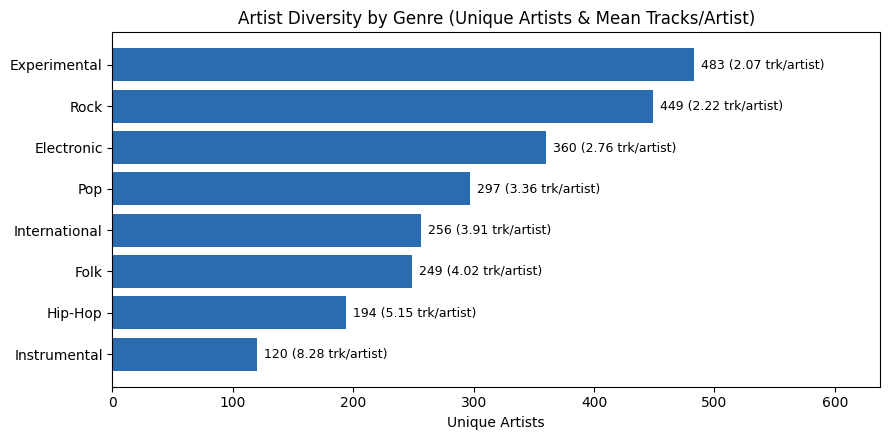

In [14]:
# VII.1 Group-Structure Audit: Artist & Album Concentration and Split Leakage Check
artist_id = clean_tracks[('artist', 'id')]
album_id = clean_tracks[('album', 'id')]
genre = clean_tracks[('track', 'genre_top')]
split = clean_tracks[('set', 'split')]

# 1. Cardinality & Concentration Summary
artist_counts = artist_id.value_counts()
album_counts = album_id.value_counts()
print("=== Group Cardinality & Concentration (Cleaned Dataset: 7,983 tracks) ===")
print(f"Unique artists : {artist_id.nunique():,} | Median tracks/artist: {artist_counts.median():.0f} | Max: {artist_counts.max()} | % tracks from multi-track artists: {(artist_counts[artist_id].values > 1).mean()*100:.1f}%")
print(f"Unique albums  : {album_id.nunique():,} | Median tracks/album : {album_counts.median():.0f} | Max: {album_counts.max()} | % tracks from multi-track albums : {(album_counts[album_id].values > 1).mean()*100:.1f}%")

# Genre-level artist diversity
group_df = pd.DataFrame({'genre': genre, 'artist_id': artist_id, 'album_id': album_id, 'split': split})
genre_artist_stats = group_df.groupby('genre').agg(
    n_tracks=('artist_id', 'size'),
    unique_artists=('artist_id', 'nunique'),
    unique_albums=('album_id', 'nunique'),
    max_tracks_per_artist=('artist_id', lambda s: s.value_counts().iloc[0]),
)
genre_artist_stats['tracks_per_artist'] = (genre_artist_stats['n_tracks'] / genre_artist_stats['unique_artists']).round(2)
print("\n=== Artist & Album Diversity by Genre ===")
display(genre_artist_stats.sort_values('unique_artists', ascending=False))

# 2. Official Split Cross-Partition Leakage Audit
print("\n=== Official Split Cross-Partition Overlap Audit ===")
for label, col in [('Artist ID', 'artist_id'), ('Album ID', 'album_id')]:
    tr_set = set(group_df.loc[group_df['split'] == 'training', col])
    va_set = set(group_df.loc[group_df['split'] == 'validation', col])
    te_set = set(group_df.loc[group_df['split'] == 'test', col])
    print(f"{label:9s} overlap -> train∩val: {len(tr_set & va_set):3d} | train∩test: {len(tr_set & te_set):3d} | val∩test: {len(va_set & te_set):3d}")

# 3. Visualize Artist Diversity by Genre
order_art = genre_artist_stats.sort_values('unique_artists', ascending=True)
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(order_art.index, order_art['unique_artists'], color='#2b6cb0')
for i, (val, tpa) in enumerate(zip(order_art['unique_artists'], order_art['tracks_per_artist'])):
    ax.text(val + 6, i, f"{val} ({tpa:.2f} trk/artist)", va='center', fontsize=9)
ax.set_xlim(0, order_art['unique_artists'].max() * 1.32)
ax.set_title("Artist Diversity by Genre (Unique Artists & Mean Tracks/Artist)")
ax.set_xlabel("Unique Artists")
plt.tight_layout()
plt.show()

**Observations (VII.1):**
- **Uneven Artist Concentration**: Across the 7,983 cleaned tracks, **85.0%** belong to multi-track artists (2,309 unique artists) and **87.6%** to multi-track albums (2,464 unique albums). **Experimental** (483 artists; 2.07 tracks/artist) and **Rock** (449 artists; 2.22 tracks/artist) are the most diverse, whereas **Instrumental** has only **120 unique artists** (8.28 tracks/artist; one artist accounts for 206 tracks), followed by **Hip-Hop** (194 artists) and **Folk** (249 artists).
- **Zero Artist Leakage Across Splits**: FMA's official `set / split` maintains **0 artist overlap** across `training`, `validation`, and `test` (0 / 0 / 0), validating the integrity of Section VI.4's test evaluation. Only a small number of multi-artist compilation `album / id` values span splits (58 train–val, 49 train–test, 21 val–test).

## **VII.2 Temporal Coverage: Upload Timeline & Split Consistency (`track / date_created`, `album / date_released`)**

Checks upload and release date coverage, verifies that the official splits span all upload years consistently, and confirms why date columns must be excluded from genre classification.

=== Temporal Coverage Summary ===
track / date_created  : 2008-11-25 to 2017-03-24 (missing: 0)
album / date_released : 1930-01-01 to 2021-03-01 (missing: 2654 / 33.2%)

=== Official Split Distribution by Upload Year ===


split,training,validation,test,train_pct
upload_year,,,,
2008,218,13,17,87.9
2009,490,63,139,70.8
2010,511,80,95,74.5
2011,745,78,63,84.1
2012,703,95,85,79.6
2013,755,106,63,81.7
2014,690,87,100,78.7
2015,1264,138,99,84.2
2016,937,139,117,78.5


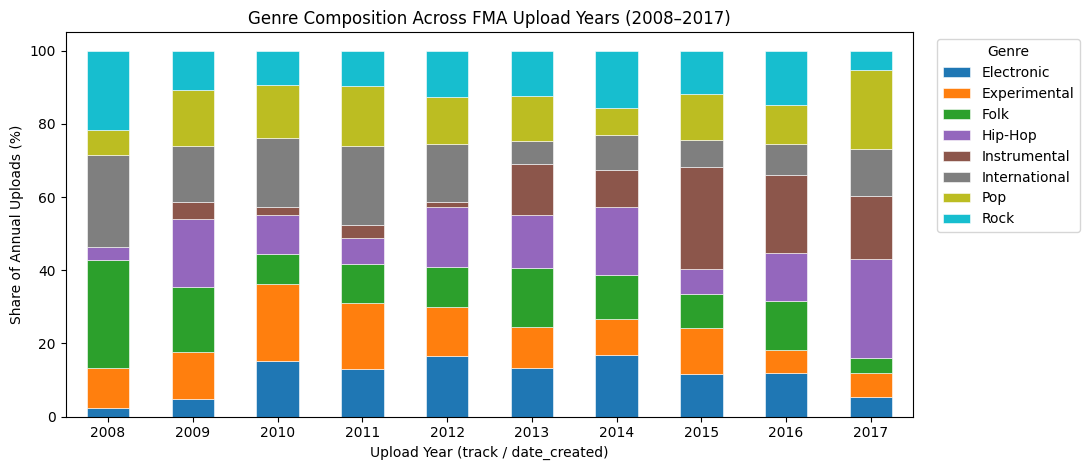

In [15]:
# VII.2 Temporal Coverage: Upload Timeline & Split Consistency
upload_dt = pd.to_datetime(clean_tracks[('track', 'date_created')], errors='coerce')
release_dt = pd.to_datetime(clean_tracks[('album', 'date_released')], errors='coerce')

temp_df = pd.DataFrame({
    'upload_year': upload_dt.dt.year,
    'release_year': release_dt.dt.year,
    'genre': clean_tracks[('track', 'genre_top')],
    'split': clean_tracks[('set', 'split')],
})

print("=== Temporal Coverage Summary ===")
print(f"track / date_created  : {upload_dt.min().date()} to {upload_dt.max().date()} (missing: {upload_dt.isna().sum()})")
print(f"album / date_released : {release_dt.min().date()} to {release_dt.max().date()} (missing: {release_dt.isna().sum()} / {release_dt.isna().mean()*100:.1f}%)")

# Split proportions across upload years
split_by_year = pd.crosstab(temp_df['upload_year'], temp_df['split'])[['training', 'validation', 'test']]
split_by_year['train_pct'] = (split_by_year['training'] / split_by_year.sum(axis=1) * 100).round(1)
print("\n=== Official Split Distribution by Upload Year ===")
display(split_by_year)

# Stacked Genre Composition by Upload Year
genre_year_pct = pd.crosstab(temp_df['upload_year'], temp_df['genre'], normalize='index') * 100
ax = genre_year_pct.plot(kind='bar', stacked=True, figsize=(11, 4.8), colormap='tab10', edgecolor='white', linewidth=0.4)
ax.set_title("Genre Composition Across FMA Upload Years (2008–2017)")
ax.set_xlabel("Upload Year (track / date_created)")
ax.set_ylabel("Share of Annual Uploads (%)")
ax.legend(title='Genre', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Observations (VII.2):**
- **Temporal Coverage**: `track / date_created` spans **2008-11-25 to 2017-03-24** (0 missing), while `album / date_released` is missing for **33.2%** of tracks (2,654 rows) and includes archival pre-2000 recordings plus one anomalous `2021-03-01` entry.
- **Catalog Upload Waves Confirm Date Exclusion**: Genre shares shift noticeably across upload years (for instance, **Instrumental** surges in 2015–2016 while **Folk** and **International** are heavier in 2008–2011). Because `set / split` draws `training` (70.8%–87.9%), `validation`, and `test` from every year rather than splitting chronologically, excluding date metadata prevents classifiers from exploiting catalog-upload timing instead of audio content.

## **VII.3 Audio-Domain Structure: Band-by-Band Random Forest Importance (`clean_features`)**

Inspects ordered acoustic indices inside the three largest audio families—20 cepstral coefficients (`mfcc`), 7 octave frequency sub-bands (`spectral_contrast`), and 12 chromatic pitch classes (`chroma_stft`)—using **Random Forest Gini importance** (from Section VI.4) for both `mean` and `std` to identify *which acoustic sub-bands* carry the strongest genre signal.

=== Band-Level Random Forest Importance (% of Total Tree Splits) ===
MFCC mean (1-5 avg)   : 0.417% | (6-10 avg): 0.198% | (11-20 avg): 0.258% | Top band: MFCC 03 (0.654%)
MFCC std  (1-5 avg)   : 0.310% | (6-10 avg): 0.310% | (11-20 avg): 0.298% | Top band: MFCC 02 (0.449%)
Spectral Contrast mean: top band 04 (0.586%), lowest band 06 (0.235%)
Spectral Contrast std : top band 04 (0.388%), lowest band 05 (0.203%)
Chroma STFT mean avg  : 0.170% (range 0.135%–0.206%)
Chroma STFT std  avg  : 0.176% (range 0.137%–0.216%)


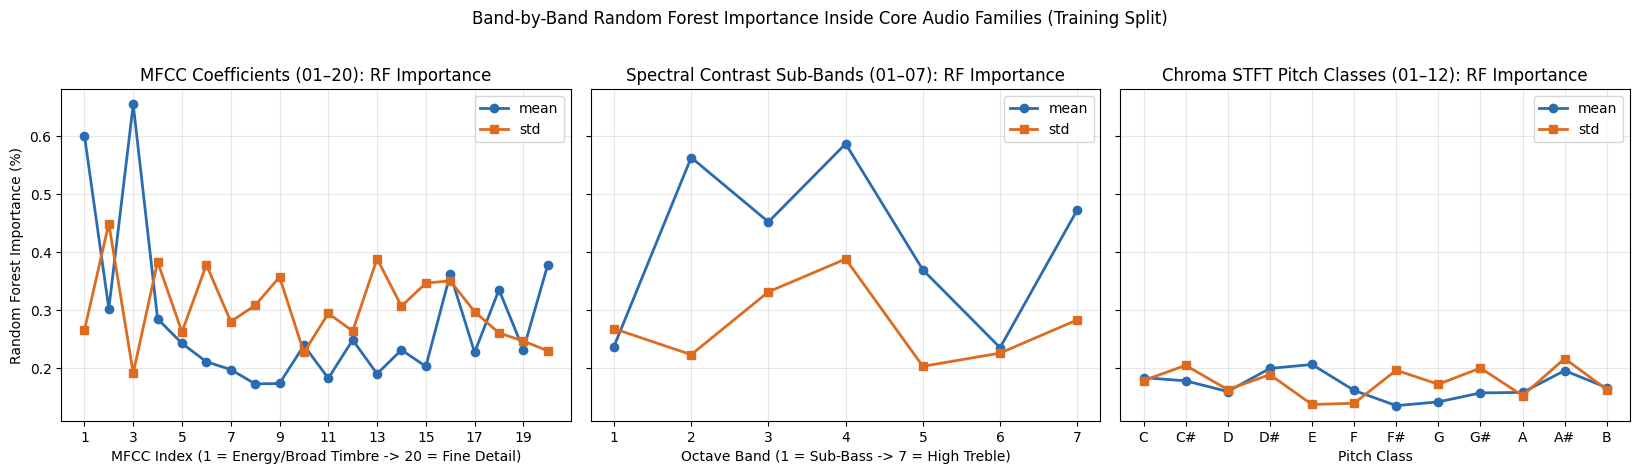

In [16]:
# VII.3 Audio-Domain Band-by-Band Importance via Random Forest: MFCC (1-20), Spectral Contrast (1-7), Chroma STFT (1-12)
from sklearn.ensemble import RandomForestClassifier

# Reuse rf_imp_series from Section VI.4 if available; otherwise fit on training split
if 'rf_imp_series' not in globals():
    train_mask = clean_tracks[('set', 'split')] == 'training'
    _rf = RandomForestClassifier(n_estimators=300, max_features='sqrt', random_state=42, n_jobs=-1)
    _rf.fit(clean_features.loc[train_mask], clean_tracks.loc[train_mask, ('track', 'genre_top')])
    rf_imp_series = pd.Series(_rf.feature_importances_, index=clean_features.columns)

def band_rf_imp(family, stat_name):
    cols = sorted([c for c in rf_imp_series.index if c[0] == family and c[1] == stat_name], key=lambda x: int(x[2]))
    return pd.Series([rf_imp_series[c] * 100 for c in cols], index=[int(c[2]) for c in cols])

mfcc_mean = band_rf_imp('mfcc', 'mean')
mfcc_std = band_rf_imp('mfcc', 'std')
sc_mean = band_rf_imp('spectral_contrast', 'mean')
sc_std = band_rf_imp('spectral_contrast', 'std')
ch_mean = band_rf_imp('chroma_stft', 'mean')
ch_std = band_rf_imp('chroma_stft', 'std')

print("=== Band-Level Random Forest Importance (% of Total Tree Splits) ===")
print(f"MFCC mean (1-5 avg)   : {mfcc_mean.loc[1:5].mean():.3f}% | (6-10 avg): {mfcc_mean.loc[6:10].mean():.3f}% | (11-20 avg): {mfcc_mean.loc[11:20].mean():.3f}% | Top band: MFCC {mfcc_mean.idxmax():02d} ({mfcc_mean.max():.3f}%)")
print(f"MFCC std  (1-5 avg)   : {mfcc_std.loc[1:5].mean():.3f}% | (6-10 avg): {mfcc_std.loc[6:10].mean():.3f}% | (11-20 avg): {mfcc_std.loc[11:20].mean():.3f}% | Top band: MFCC {mfcc_std.idxmax():02d} ({mfcc_std.max():.3f}%)")
print(f"Spectral Contrast mean: top band {sc_mean.idxmax():02d} ({sc_mean.max():.3f}%), lowest band {sc_mean.idxmin():02d} ({sc_mean.min():.3f}%)")
print(f"Spectral Contrast std : top band {sc_std.idxmax():02d} ({sc_std.max():.3f}%), lowest band {sc_std.idxmin():02d} ({sc_std.min():.3f}%)")
print(f"Chroma STFT mean avg  : {ch_mean.mean():.3f}% (range {ch_mean.min():.3f}%–{ch_mean.max():.3f}%)")
print(f"Chroma STFT std  avg  : {ch_std.mean():.3f}% (range {ch_std.min():.3f}%–{ch_std.max():.3f}%)")

# Plot 1x3 Band-by-Band Random Forest Importance Profiles
fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.6), sharey=True)

axes[0].plot(mfcc_mean.index, mfcc_mean.values, marker='o', linewidth=2, label='mean', color='#2b6cb0')
axes[0].plot(mfcc_std.index, mfcc_std.values, marker='s', linewidth=2, label='std', color='#dd6b20')
axes[0].set_title("MFCC Coefficients (01–20): RF Importance")
axes[0].set_xlabel("MFCC Index (1 = Energy/Broad Timbre -> 20 = Fine Detail)")
axes[0].set_ylabel("Random Forest Importance (%)")
axes[0].set_xticks(range(1, 21, 2))
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(sc_mean.index, sc_mean.values, marker='o', linewidth=2, label='mean', color='#2b6cb0')
axes[1].plot(sc_std.index, sc_std.values, marker='s', linewidth=2, label='std', color='#dd6b20')
axes[1].set_title("Spectral Contrast Sub-Bands (01–07): RF Importance")
axes[1].set_xlabel("Octave Band (1 = Sub-Bass -> 7 = High Treble)")
axes[1].set_xticks(range(1, 8))
axes[1].legend()
axes[1].grid(alpha=0.3)

pitch_labels = ['C', 'C#', 'D', 'D#', 'E', 'F', 'F#', 'G', 'G#', 'A', 'A#', 'B']
axes[2].plot(ch_mean.index, ch_mean.values, marker='o', linewidth=2, label='mean', color='#2b6cb0')
axes[2].plot(ch_std.index, ch_std.values, marker='s', linewidth=2, label='std', color='#dd6b20')
axes[2].set_title("Chroma STFT Pitch Classes (01–12): RF Importance")
axes[2].set_xlabel("Pitch Class")
axes[2].set_xticks(range(1, 13))
axes[2].set_xticklabels(pitch_labels)
axes[2].legend()
axes[2].grid(alpha=0.3)

plt.suptitle("Band-by-Band Random Forest Importance Inside Core Audio Families (Training Split)", y=1.02)
plt.tight_layout()
plt.show()

**Observations (VII.3):**
- **All 20 MFCCs Contribute to Genre Classification**: Lower-order `mfcc / mean` coefficients (`01–05`, avg **0.417%**, led by `mfcc / mean / 03` at **0.654%**) carry the strongest single-band importance, while higher-order coefficients remain informative (`11–20` avg **0.258%**, exceeding `06–10` at **0.198%**). Even more notably, `mfcc / std` stays nearly constant across the entire cepstral spectrum (`01–05`: **0.310%**, `06–10`: **0.310%**, `11–20`: **0.298%**; peaking at `mfcc / std / 02` with **0.449%**), showing why retaining all 20 MFCC bands beats speech-style truncation at 12–13.
- **Mid-Frequency Dominance in `spectral_contrast`**: Random Forest importance peaks sharply at **mid-frequency band `04`** (**0.586%** for `mean`, **0.388%** for `std`—where vocals, guitars, and melodic instruments sit) and drops lowest at **bands `05–06`** (**0.203%–0.235%**).
- **Flat Importance Across `chroma_stft` Pitch Classes**: Importance stays low and nearly uniform across all 12 pitch classes (`mean` avg **0.170%**, range `0.135%–0.206%`; `std` avg **0.176%**, range `0.137%–0.216%`), confirming that individual musical keys do not define genre.

## **VII.4 Taxonomy & Text Metadata Summary (`track / genres_all`, `track / tags`, `track / title`)**

Examines multi-genre label breadth (`track / genres_all`) and user tag sparsity (`track / tags`) to explain cross-genre overlap in our **Logistic Regression**, **Random Forest**, and **Hierarchical Clustering** results and confirm why audio features remain indispensable over sparse text metadata.

=== Sub-Genre Taxonomy & Text Coverage by Top-Level Genre ===


,unique_subgenres,avg_labels_per_track,pct_multi_label,pct_with_tags,avg_title_words
genre,,,,,
Electronic,19,2.98,92.15,23.77,2.62
International,26,2.36,92.00,18.90,2.82
Rock,29,3.02,89.29,16.02,2.62
Experimental,19,2.47,88.09,25.53,3.33
Instrumental,5,2.02,85.21,18.31,2.67
Pop,3,1.58,52.81,13.93,2.77
Folk,6,1.54,46.80,10.00,2.82
Hip-Hop,7,1.49,40.20,9.40,3.37



Overall track / tags coverage: 17.0% (1,355 / 7,983 tracks) | Unique tags: 1,191
Top 10 user tags: [('electronic', 145), ('instrumental', 140), ('experimental', 98), ('acoustic', 84), ('soundtrack', 71), ('electronica', 70), ('folk', 66), ('ambient', 65), ('tracks to sync', 63), ('pop', 52)]


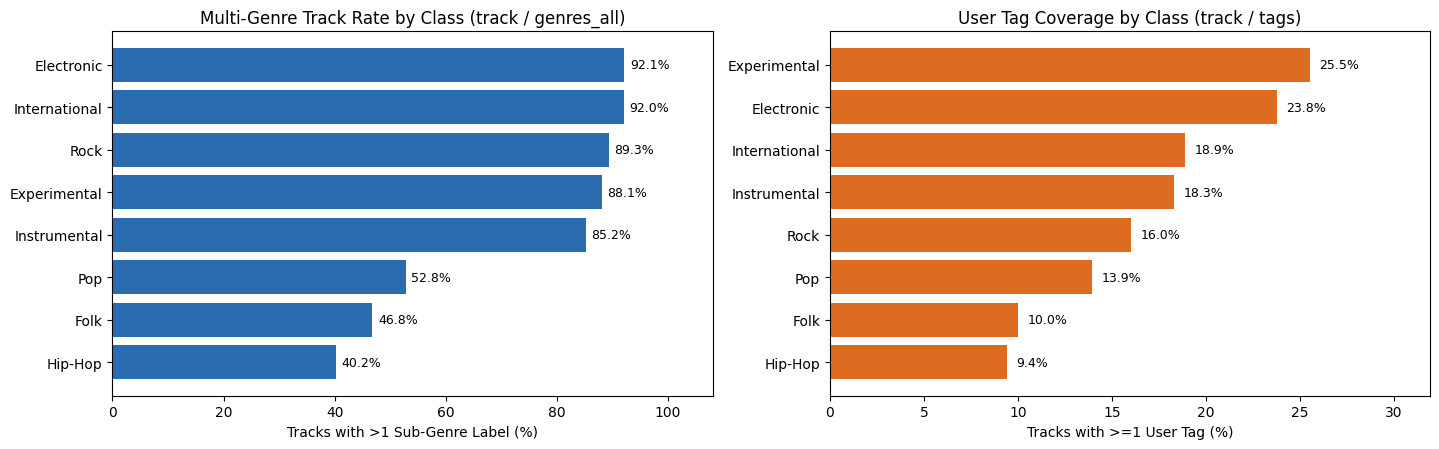

In [17]:
# VII.4 Taxonomy & Text Metadata Summary: Multi-Genre Complexity & Tag Sparsity
import ast
from collections import Counter

def safe_parse_list(val):
    if isinstance(val, list):
        return val
    if pd.isna(val):
        return []
    try:
        parsed = ast.literal_eval(str(val))
        return parsed if isinstance(parsed, list) else []
    except Exception:
        return []

genre = clean_tracks[('track', 'genre_top')]
genres_all = clean_tracks[('track', 'genres_all')].apply(safe_parse_list)
tags_parsed = clean_tracks[('track', 'tags')].apply(safe_parse_list)
titles = clean_tracks[('track', 'title')].fillna('').astype(str)

tax_df = pd.DataFrame({
    'genre': genre,
    'n_subgenres': genres_all.apply(len),
    'has_multi_genre': genres_all.apply(lambda x: len(x) > 1),
    'has_tags': tags_parsed.apply(lambda x: len(x) > 0),
    'title_words': titles.str.split().str.len(),
})

genre_tax_summary = tax_df.groupby('genre').agg(
    avg_labels_per_track=('n_subgenres', 'mean'),
    pct_multi_label=('has_multi_genre', lambda s: s.mean() * 100),
    pct_with_tags=('has_tags', lambda s: s.mean() * 100),
    avg_title_words=('title_words', 'mean'),
)
genre_tax_summary['unique_subgenres'] = [
    len(set(g for sub in genres_all.loc[genre == grp] for g in sub))
    for grp in genre_tax_summary.index
]
genre_tax_summary = genre_tax_summary[['unique_subgenres', 'avg_labels_per_track', 'pct_multi_label', 'pct_with_tags', 'avg_title_words']]

print("=== Sub-Genre Taxonomy & Text Coverage by Top-Level Genre ===")
display(genre_tax_summary.sort_values('pct_multi_label', ascending=False).round(2))

all_tags = [str(t).strip().lower() for row in tags_parsed for t in row if str(t).strip()]
print(f"\nOverall track / tags coverage: {tax_df['has_tags'].mean()*100:.1f}% ({tax_df['has_tags'].sum():,} / {len(tax_df):,} tracks) | Unique tags: {len(set(all_tags)):,}")
print("Top 10 user tags:", Counter(all_tags).most_common(10))

# Visualize Multi-Label Rate vs. Tag Coverage
fig, axes = plt.subplots(1, 2, figsize=(14.5, 4.6))
order_ml = genre_tax_summary.sort_values('pct_multi_label', ascending=True)
axes[0].barh(order_ml.index, order_ml['pct_multi_label'], color='#2b6cb0')
for i, v in enumerate(order_ml['pct_multi_label']):
    axes[0].text(v + 1, i, f"{v:.1f}%", va='center', fontsize=9)
axes[0].set_xlim(0, 108)
axes[0].set_title("Multi-Genre Track Rate by Class (track / genres_all)")
axes[0].set_xlabel("Tracks with >1 Sub-Genre Label (%)")

order_tag = genre_tax_summary.sort_values('pct_with_tags', ascending=True)
axes[1].barh(order_tag.index, order_tag['pct_with_tags'], color='#dd6b20')
for i, v in enumerate(order_tag['pct_with_tags']):
    axes[1].text(v + 0.5, i, f"{v:.1f}%", va='center', fontsize=9)
axes[1].set_xlim(0, order_tag['pct_with_tags'].max() * 1.25)
axes[1].set_title("User Tag Coverage by Class (track / tags)")
axes[1].set_xlabel("Tracks with >=1 User Tag (%)")

plt.tight_layout()
plt.show()

**Observations (VII.4):**
- **Widespread Multi-Genre Overlap Explains Classifier Confusions**: Most top-level genres encompass many sub-genres and multi-label tracks—especially **Electronic** (`92.15%` multi-label, 19 sub-genres), **International** (`92.00%`, 26 sub-genres), **Rock** (`89.29%`, 29 sub-genres), **Experimental** (`88.09%`, 19 sub-genres), and **Instrumental** (`85.21%`). Collapsing inherently multi-genre tracks into one top-level label helps explain why both supervised classifiers (`~45–49%` test accuracy) and unsupervised Hierarchical Clustering (`28.04%` purity) experience overlap among crossover classes.
- **User Tags Are Too Sparse—and Leak Targets**: Only **17.0%** of tracks (`1,355 / 7,983`) have any user tag in `track / tags` (dropping to `9.4%` in Hip-Hop and `10.0%` in Folk), while the most frequent tags directly echo genre names (`electronic`, `instrumental`, `experimental`, `folk`, `pop`, `rock`). Keeping classification strictly on `clean_features` avoids both missingness and direct label leakage.

### **Summary & Key Takeaways (Section VII — Type-Specific Insights)**
- **Leakage-Safe Group & Temporal Splits**: Official FMA partitions have **zero cross-split artist overlap** (0 / 0 / 0) and cover every upload year, confirming that excluding `artist / id`, `album / id`, dates, and `tags` keeps evaluation honest. Because 85.0% of tracks come from multi-track artists (especially **Instrumental** with 120 unique artists), any cross-validation inside `training` should group by `artist / id`.
- **Band-Level Audio Insights (via Random Forest)**: All **20 MFCC coefficients** (especially `mfcc / mean / 01–05` and `mfcc / std / 01–20`) and **mid-band `spectral_contrast` (band `04`)** carry the strongest genre signal, while individual `chroma_stft` pitch classes are flat and low-impact.
- **Taxonomic Context for Overlap**: High multi-genre rates (`40.2%–92.2%`) clarify why crossover classes (**Experimental**, **Folk**, **Pop**, **International**) are harder to separate under single-label classification and clustering.

# **VIII. Summary of Findings**

This notebook audited, cleaned, explored, and mined the **FMA-Small** dataset (`tracks.csv` and `features.csv`) to evaluate **the importance of audio features in music genre classification** using three focused data mining techniques—**Logistic Regression**, **Random Forest**, and **Hierarchical Clustering**. Five core findings stand out:

### **1. Clean, Balanced, and Leakage-Safe Benchmark Dataset**
- Removing **17 duplicate feature rows** and **8 metadata columns (>90% missing)** yields `clean_features` (`7,983 × 518`) and `clean_tracks` (`7,983 × 44`) aligned 1-to-1 with **0 missing audio values** and **0 missing labels**.
- `track / genre_top` is balanced across all 8 genres (~12.4–12.5% each), and FMA's official `set / split` (`6,391` training / `800` validation / `792` test) maintains clean genre balance ($p = 1.000$) with **zero cross-split artist overlap**.

### **2. Random Forest Outperforms Logistic Regression on Held-Out Genre Classification**
- Trained strictly on the 518 `librosa` audio features, **Random Forest (300 trees)** achieves **48.99% Test Accuracy** (**0.4900** Macro-F1; Validation: **54.87%** / **0.5313**), outperforming L2-regularized **Logistic Regression ($C=0.01$)** (**45.45%** Test Accuracy / **0.4528** Macro-F1; Validation: **54.37%** / **0.5348**) by **+3.54 percentage points**.
- Both classifiers clearly beat the 12.5% random baseline (~3.6×–3.9×), performing strongest on **Rock** (RF F1 = `0.680`), **Hip-Hop** (LR = `0.696`, RF = `0.654`), and **Electronic** (RF = `0.597`), while **Folk** (`0.242`) and **Experimental** (`0.267–0.365`) show the highest test confusion.

### **3. Timbre (`mfcc`), Spectral Contrast, and Variability (`std`) Drive Feature Importance**
- Both **Random Forest** and **Logistic Regression** identify **`mfcc`** (**34.35%** RF / **32.29%** LR) and **`spectral_contrast`** (**13.88%** RF / **12.44%** LR) as the dominant non-harmonic families (**48.23%** combined RF share).
- Per individual feature, the compact 7-feature spectral and loudness families (`spectral_rolloff`, `spectral_centroid`, `spectral_bandwidth`, `rmse`) carry the highest signal density, while **`std`** is the #1 summary statistic in both models (**18.08%** RF / **18.76%** LR).
- Band-by-band **Random Forest** analysis (Section VII.3) shows all **20 MFCC coefficients** and **mid-frequency `spectral_contrast` band `04`** carry strong signal, whereas individual `chroma_stft` pitch classes contribute little on their own.

### **4. Hierarchical Clustering Reveals Three Natural Acoustic Macro-Families**
- Genre-level **Ward Hierarchical Clustering** organizes the 8 genres into three clear acoustic groups: **(1) Electronic + Hip-Hop** (Ward distance `3.94`), **(2) International + Pop + Experimental + Rock** (`4.12–8.42`), and **(3) Folk + Instrumental** (`5.25`, remaining separated until the final merge at `15.33`).
- Track-level **Agglomerative Clustering** ($k = 8$) reaches **28.04% purity** (`ARI = 0.0789`, `NMI = 0.1173`)—more than double random chance, yet well below supervised classification—confirming that labeled supervision is needed to separate overlapping crossover genres.

### **5. Metadata Confounds & Multi-Genre Taxonomy Explain Classification Limits**
- Technical and catalog metadata (`bit_rate`, `duration`, upload dates, and sparse `tags` at 17.0% coverage) vary by genre or echo label names and must stay excluded.
- Multi-genre labeling (`40.2%–92.2%` of tracks) and artist concentration (85.0% multi-track artists; 120 unique artists in Instrumental) explain why acoustic overlap caps single-label tabular accuracy near ~50%.

### **Data Mining & Feature Importance Synthesis Table**

| Analysis Area | Method Used | Key Quantitative Finding | Modeling / Domain Takeaway |
| :--- | :--- | :--- | :--- |
| **Data & Split Integrity (IV–VI.1, VII.1)** | Cleaning, Split & Artist Audit | `7,983 × 518` clean features; 8 balanced genres; `0` cross-split artist overlap | Official split is leakage-free; exclude `bit_rate`, dates, and `tags` |
| **Feature Redundancy (VI.2)** | Correlation Audit | `204 / 518` features (`39.4%`) have a collinear partner at $|r| \ge 0.85$ | Explains why strong L2 regularization ($C = 0.01$) helps Logistic Regression |
| **Supervised Classification (VI.4)** | **Logistic Regression** & **Random Forest** | RF: **48.99%** Test Acc (`0.4900` F1) vs. LR: **45.45%** (`0.4528` F1) | Non-linear tree ensembles generalize better across artist-disjoint test tracks |
| **Audio Feature Importance (VI.4, VII.3)** | **Random Forest** & **Logistic Regression** | `mfcc` (`34.35%`) + `spectral_contrast` (`13.88%`) = `48.23%` RF share; `std` #1 stat (`18.08%`) | Keep all 20 MFCCs, mid-band `spectral_contrast` (`04`), spectral shape, and `std` |
| **Unsupervised Structure (VI.5)** | **Hierarchical Clustering (Ward)** | 3 macro-families (*Elec/Hip-Hop*, *Intl/Pop/Exp/Rock*, *Folk/Inst*); track purity **28.04%** | Broad acoustic families exist, but supervision is needed for fine genre boundaries |

# **IX. Limitations and Next Steps**

While our three data mining techniques (**Logistic Regression**, **Random Forest**, and **Hierarchical Clustering**) establish clear, leakage-free benchmarks and feature-importance rankings on FMA-Small, several boundaries remain for future work.

## **IX.1 Limitations**

1. **Temporal Structure Lost in 30-Second Summary Statistics**: `features.csv` collapses 30-second audio clips into 7 global frame statistics (`mean`, `std`, `median`, `min`, `max`, `skew`, `kurtosis`), discarding beat periodicity, tempo progression, and song-section dynamics.
2. **Single-Label Target on Multi-Genre Music**: Between **40.2% (Hip-Hop)** and **92.2% (Electronic)** of tracks carry multiple sub-genres in `track / genres_all`. Evaluating against a single `genre_top` label creates irreducible ambiguity for crossover genres (**Pop**, **International**, **Experimental**, and **Folk**).
3. **Artist Concentration & Validation-to-Test Generalization Gap**: Although the official split has zero cross-split artist overlap, uneven artist concentration (e.g., **Instrumental** has 120 unique artists, one with 206 tracks) contributes to the drop from `validation` (~54–55%) to `test` (~45–49%).
4. **Multicollinearity in Feature Importance**: Because 39.4% of features share high linear correlation ($|r| \ge 0.85$), tree split importance and linear coefficients can spread weight across correlated descriptors (for example, `spectral_centroid` vs. `spectral_rolloff`).

## **IX.2 Next Steps**

1. **Feature-Family Ablation Study**: Re-train **Random Forest** and **Logistic Regression** on isolated subsets (`MFCC only`, `Spectral Shape & Contrast only`, `Chroma + Tonnetz only`, and `MFCC + Spectral + RMSE`) to quantify each family's direct Test Macro-F1 contribution.
2. **Group-Aware Hyperparameter Tuning**: Tune **Random Forest** depth/leaf constraints and **Logistic Regression** penalties using **`GroupKFold` grouped by `artist / id`** inside `training` to reduce the validation-to-test generalization gap.
3. **Expand Model Comparisons**: Benchmark additional classifiers such as **RBF-kernel SVM** or **kNN**, and optionally compare tabular `librosa` features against raw-audio Mel-spectrogram CNNs from `fma_small` to evaluate the interpretability-vs.-accuracy trade-off.

# **X. References**

### **Dataset & Repository**
- Defferrard, M., Benzi, K., Vandergheynst, P., & Bresson, X. (2017). FMA: A Dataset for Music Analysis. In *Proceedings of the 18th International Society for Music Information Retrieval Conference (ISMIR 2017)*, 316–323. https://arxiv.org/abs/1612.01840
- Defferrard, M. (2017). *FMA: A Dataset for Music Analysis* [Software and dataset repository]. GitHub. https://github.com/mdeff/fma

### **Audio Feature Extraction & Music Information Retrieval (MIR)**
- Flexer, A., & Schnitzer, D. (2009). Album and artist effects for audio similarity at the scale of the web. In *Proceedings of the 6th Sound and Music Computing Conference (SMC 2009)*, 59–64.
- Harte, C., Sandler, M., & Gasser, M. (2006). Detecting harmonic change in musical audio. In *Proceedings of the 1st ACM Workshop on Audio and Music Computing Multimedia (AMCMM 2006)*, 21–26. https://doi.org/10.1145/1178723.1178727
- Jiang, D.-N., Lu, L., Zhang, H.-J., Tao, J.-H., & Cai, L.-H. (2002). Music type classification by spectral contrast feature. In *Proceedings of the IEEE International Conference on Multimedia and Expo (ICME 2002)*, 1, 113–116. https://doi.org/10.1109/ICME.2002.1035731
- McFee, B., Raffel, C., Liang, D., Ellis, D. P. W., McVicar, M., Battenberg, E., & Nieto, O. (2015). librosa: Audio and music signal analysis in Python. In *Proceedings of the 14th Python in Science Conference (SciPy 2015)*, 18–25. https://doi.org/10.25080/Majora-7b98e3ed-003
- Tzanetakis, G., & Cook, P. (2002). Musical genre classification of audio signals. *IEEE Transactions on Speech and Audio Processing*, 10(5), 293–302. https://doi.org/10.1109/TSA.2002.800560

### **Data Mining Methods**
- Breiman, L. (2001). Random forests. *Machine Learning*, 45(1), 5–32. https://doi.org/10.1023/A:1010933404324
- Cox, D. R. (1958). The regression analysis of binary sequences. *Journal of the Royal Statistical Society: Series B (Methodological)*, 20(2), 215–232.
- Hosmer, D. W., Lemeshow, S., & Sturdivant, R. X. (2013). *Applied Logistic Regression* (3rd ed.). John Wiley & Sons.
- Ward, J. H., Jr. (1963). Hierarchical grouping to optimize an objective function. *Journal of the American Statistical Association*, 58(301), 236–244. https://doi.org/10.1080/01621459.1963.10500845

### **Python Libraries & Software Tools**
- Harris, C. R., Millman, K. J., van der Walt, S. J., Gommers, R., Virtanen, P., Cournapeau, D., Wieser, E., Taylor, J., Berg, S., Smith, N. J., Kern, R., Picus, M., Hoyer, S., van Kerkwijk, M. H., Brett, M., Haldane, A., Fernández del Río, J., Wiebe, M., Peterson, P., ... Oliphant, T. E. (2020). Array programming with NumPy. *Nature*, 585(7825), 357–362. https://doi.org/10.1038/s41586-020-2649-2
- Hunter, J. D. (2007). Matplotlib: A 2D graphics environment. *Computing in Science & Engineering*, 9(3), 90–95. https://doi.org/10.1109/MCSE.2007.55
- McKinney, W. (2010). Data structures for statistical computing in Python. In *Proceedings of the 9th Python in Science Conference (SciPy 2010)*, 56–61. https://doi.org/10.25080/Majora-92bf1922-00a
- Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M., & Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research*, 12, 2825–2830.
- Virtanen, P., Gommers, R., Oliphant, T. E., Haberland, M., Reddy, T., Cournapeau, D., Burovski, E., Peterson, P., Weckesser, W., Bright, J., van der Walt, S. J., Brett, M., Wilson, J., Millman, K. J., Mayorov, N., Nelson, A. R. J., Jones, E., Kern, R., Larson, E., ... SciPy 1.0 Contributors. (2020). SciPy 1.0: Fundamental algorithms for scientific computing in Python. *Nature Methods*, 17(3), 261–272. https://doi.org/10.1038/s41592-019-0686-2
- Waskom, M. L. (2021). seaborn: Statistical data visualization. *Journal of Open Source Software*, 6(60), 3021. https://doi.org/10.21105/joss.03021